In [1]:
import pandas as pd
import pickle
import os
import time

import math
import random
import shutil
import pathlib
import seaborn as sns
import numpy as np
from numpy import where
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib import pyplot
import os
import time
from imblearn.over_sampling import ADASYN
from collections import (Counter, defaultdict)
import tensorflow as tf
from scipy import stats
from tensorflow.keras import layers
#from tensorflow.python import train
from keras.models import Sequential
from keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE
import keras.callbacks as kcallbacks
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import (QuantileTransformer, LabelEncoder)
from sklearn.metrics import (det_curve, balanced_accuracy_score, cohen_kappa_score, hinge_loss, matthews_corrcoef, 
                             top_k_accuracy_score, hamming_loss, jaccard_score, log_loss, zero_one_loss, classification_report,
                             accuracy_score, precision_score, roc_auc_score, average_precision_score, recall_score, f1_score, 
                             mean_squared_error, mean_absolute_error, confusion_matrix, r2_score)

2024-02-08 20:25:52.983079: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-02-08 20:25:53.021312: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-02-08 20:25:53.021331: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-02-08 20:25:53.021349: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-02-08 20:25:53.028444: I tensorflow/core/platform/cpu_feature_g

# MobileNetV2

In [ ]:
img_height = 224
img_width = 224

train_ds = tf.data.Dataset.load("saved_data/train")
val_ds = tf.data.Dataset.load("saved_data/validation")
test_ds = tf.data.Dataset.load("saved_data/test")

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

In [283]:
IMG_SHAPE = (img_height, img_width,3)
base_model_MobileNetV2 = tf.keras.applications.MobileNetV2(input_shape=IMG_SHAPE, include_top=False, weights='imagenet')

In [284]:
base_model_MobileNetV2.trainable = False
base_model_MobileNetV2.summary()

Model: "mobilenetv2_1.00_224"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_25 (InputLayer)       [(None, 224, 224, 3)]        0         []                            
                                                                                                  
 Conv1 (Conv2D)              (None, 112, 112, 32)         864       ['input_25[0][0]']            
                                                                                                  
 bn_Conv1 (BatchNormalizati  (None, 112, 112, 32)         128       ['Conv1[0][0]']               
 on)                                                                                              
                                                                                                  
 Conv1_relu (ReLU)           (None, 112, 112, 32)         0         ['bn_Conv1[

In [285]:
image_batch, label_batch = next(iter(train_ds))
feature_batch_MobileNetV2 = base_model_MobileNetV2(image_batch)
print(feature_batch_MobileNetV2.shape)
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
feature_batch_average_MobileNetV2 = global_average_layer(feature_batch_MobileNetV2)
print(feature_batch_average_MobileNetV2.shape)
prediction_layer_MobileNetV2 = tf.keras.layers.Dense(1)
prediction_batch_MobileNetV2 = prediction_layer_MobileNetV2(feature_batch_average_MobileNetV2)
print(prediction_batch_MobileNetV2.shape)

(32, 7, 7, 1280)
(32, 1280)
(32, 1)


In [286]:
inputs_MobileNetV2 = tf.keras.Input(shape=(img_height, img_width,3))  
x_MobileNetV2 = data_augmentation(inputs_MobileNetV2)   
x_MobileNetV2 = tf.keras.applications.mobilenet.preprocess_input(x_MobileNetV2)  
x_MobileNetV2 = base_model_MobileNetV2(x_MobileNetV2, training=False)
x_MobileNetV2 = global_average_layer(x_MobileNetV2)
x_MobileNetV2 = tf.keras.layers.Dropout(0.2)(x_MobileNetV2) 
outputs_MobileNetV2 = prediction_layer_MobileNetV2(x_MobileNetV2)
model_MobileNetV2 = tf.keras.Model(inputs_MobileNetV2, outputs_MobileNetV2)

In [287]:
class LossHistory(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs={}):
        self.losses = {'batch':[], 'epoch':[]}
        self.accuracy = {'batch':[], 'epoch':[]}
        self.val_loss = {'batch':[], 'epoch':[]}
        self.val_acc = {'batch':[], 'epoch':[]}
        self.history = {}
    def on_batch_end(self, batch, logs={}):
        self.losses['batch'].append(logs.get('loss'))
        self.accuracy['batch'].append(logs.get('accuracy'))
        self.val_loss['batch'].append(logs.get('val_loss'))
        self.val_acc['batch'].append(logs.get('val_accuracy'))
    def on_epoch_end(self, batch, logs={}):
        self.losses['epoch'].append(logs.get('loss'))
        self.accuracy['epoch'].append(logs.get('accuracy'))
        self.val_loss['epoch'].append(logs.get('val_loss'))
        self.val_acc['epoch'].append(logs.get('val_accuracy'))
        self.history = {'loss': self.losses, 'accuracy': self.accuracy, 'val_loss': self.val_loss, 'val_accuracy': self.val_acc}

In [288]:
history= LossHistory()
base_learning_rate = 0.00007
savepath='./MobileNetV2.h5'
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
saveBestModel = kcallbacks.ModelCheckpoint(filepath=savepath, verbose=1, save_best_only=True, mode='auto')
model_MobileNetV2.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
              loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [289]:
model_MobileNetV2.summary()

Model: "model_12"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_26 (InputLayer)       [(None, 224, 224, 3)]     0         
                                                                 
 sequential (Sequential)     (None, 224, 224, 3)       0         
                                                                 
 tf.math.truediv_12 (TFOpLa  (None, 224, 224, 3)       0         
 mbda)                                                           
                                                                 
 tf.math.subtract_12 (TFOpL  (None, 224, 224, 3)       0         
 ambda)                                                          
                                                                 
 mobilenetv2_1.00_224 (Func  (None, 7, 7, 1280)        2257984   
 tional)                                                         
                                                          

In [290]:
initial_epochs = 5
loss0, accuracy0 = model_MobileNetV2.evaluate(val_ds)

36/36 [==============================] - 2s 19ms/step - loss: 0.9470 - accuracy: 0.5710


In [291]:
print("initial loss: {:.4f}".format(loss0))
print("initial accuracy: {:.4f}".format(accuracy0))

initial loss: 0.9470
initial accuracy: 0.5710


In [292]:
%%time
history_MobileNetV2 = model_MobileNetV2.fit(train_ds,epochs=initial_epochs,validation_data=val_ds, 
                                            callbacks=[early_stop, saveBestModel, history])

# Inference (Detection)
start_time = time.time()
detection_results = model_MobileNetV2.predict(val_ds)
end_time = time.time()

detection_time = end_time - start_time

print(f"Detection time: {detection_time} seconds")

Epoch 1/5
211/213 [============================>.] - ETA: 0s - loss: 0.4716 - accuracy: 0.7475
Epoch 1: val_loss improved from inf to 0.25945, saving model to ./MobileNetV2.h5
213/213 [==============================] - 7s 25ms/step - loss: 0.4691 - accuracy: 0.7497 - val_loss: 0.2595 - val_accuracy: 0.9298
Epoch 2/5
  1/213 [..............................] - ETA: 4s - loss: 0.1700 - accuracy: 0.9688

/usr/local/lib/python3.9/site-packages/keras/src/engine/training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


211/213 [============================>.] - ETA: 0s - loss: 0.1566 - accuracy: 0.9655
Epoch 2: val_loss improved from 0.25945 to 0.13975, saving model to ./MobileNetV2.h5
213/213 [==============================] - 5s 24ms/step - loss: 0.1566 - accuracy: 0.9655 - val_loss: 0.1397 - val_accuracy: 0.9840
Epoch 3/5
211/213 [============================>.] - ETA: 0s - loss: 0.0990 - accuracy: 0.9828
Epoch 3: val_loss improved from 0.13975 to 0.10552, saving model to ./MobileNetV2.h5
213/213 [==============================] - 5s 24ms/step - loss: 0.0991 - accuracy: 0.9828 - val_loss: 0.1055 - val_accuracy: 0.9831
Epoch 4/5
211/213 [============================>.] - ETA: 0s - loss: 0.0781 - accuracy: 0.9855
Epoch 4: val_loss improved from 0.10552 to 0.09060, saving model to ./MobileNetV2.h5
213/213 [==============================] - 5s 24ms/step - loss: 0.0784 - accuracy: 0.9853 - val_loss: 0.0906 - val_accuracy: 0.9831
Epoch 5/5
211/213 [============================>.] - ETA: 0s - loss: 0.068

In [293]:
acc_MobileNetV2 = history_MobileNetV2.history['accuracy']
val_acc_MobileNetV2 = history_MobileNetV2.history['val_accuracy']
loss_MobileNetV2 = history_MobileNetV2.history['loss']
val_loss_MobileNetV2 = history_MobileNetV2.history['val_loss']

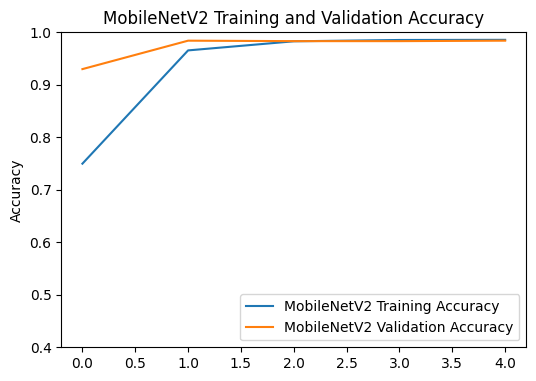

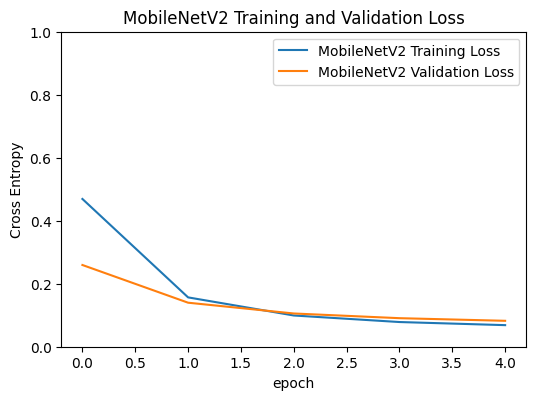

In [294]:
plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 1)
plt.plot(acc_MobileNetV2, label='MobileNetV2 Training Accuracy')
plt.plot(val_acc_MobileNetV2, label='MobileNetV2 Validation Accuracy')
plt.ylim([0.4, 1.01])
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),1])
plt.title('MobileNetV2 Training and Validation Accuracy')
plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 2)
plt.plot(loss_MobileNetV2, label='MobileNetV2 Training Loss')
plt.plot(val_loss_MobileNetV2, label='MobileNetV2 Validation Loss')
plt.ylim([-0.02, 1.02])
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0,1.0])

plt.title('MobileNetV2 Training and Validation Loss')
plt.xlabel('epoch')
plt.savefig('MobileNetV2_Full.pdf', format='pdf', dpi=300)
plt.savefig('MobileNetV2_Full.svg', format='svg')
plt.savefig('MobileNetV2_Full.png', format='png', dpi=300)
plt.show()

## Test_ds (MobileNetV2)

Predictions:
 [0 0 0 0 1 0 1 1 0 1 1 1 0 1 1 1 0 1 0 0 0 0 0 1 1 1 1 1 0 1 1 0 1 0 1 0 0
 1 1 1 0 1 1 1 0 0 0 1 1 0 1 1 0 0 1 0 0 0 0 1 1 1 0 1 1 0 0 0 1 0 1 0 0 0
 0 1 0 0 1 1 0 1 0 1 0 1 0 1 0 0 1 0 0 1 0 1 0 1 0 0 1 1 1 1 1 1 0 0 0 0 0
 0 0 0 1 1 0 0 0 1 1 1 1 0 0 0 0 1 0 0 0 0 1 0 0 0 1 0 0 1 0 0 1 1 0 0 0 1
 1 0 0 0 0 1 0 0 0 1 1 0 0 0 0 0 0 1 1 1 1 0 0 0 1 1 1 1 0 1 0 1 0 1 0 0 1
 1 1 1 0 0 1 1 0 0 0 1 0 0 0 1 1 1 0 1 1 0 1 0 0 1 1 0 1 0 1 0 1 0 0 1 0 0
 1 0 1 0 1 0 0 0 0 0 0 0 1 1 0 0 0 1 0 0 0 1 1 0 1 0 1 0 0 0 0 1 0 0 1 0 0
 0 1 1 0 0 0 0 1 0 1 1 0 0 1 0 0 0 1 1 0 0 0 1 0 1 1 0 0 0 1 1 1 0 0 1 0 1
 0 1 1 0 1 0 1 1 0 1 1 0 0 0 1 0 0 1 0 1 1 0 1 0 1 0 1 0 0 0 0 1 0 1 0 0 0
 0 0 0 0 1 0 0 1 0 1 1 1 1 0 1 0 0 1 0 1 0 0 0 1 0 1 1 0 0 1 0 1 1 0 0 0 0
 0 0 0 0 1 1 0 0 1 0 1 0 0 0 0 0 1 1 1 1 0 0 1 1 1 0 1 0 0 0 1 0 0 0 1 1 0
 0 0 1 0 0 0 0 1 0 0 0 0 0 0 1 0 1 1 1 0 0 1 0 0 1 0 1 0 0 1 0 0 0 0 0 0 1
 1 0 1 1 0 1 1 0 0 0 1 1 1 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 1 0 0 0 1
 0 0 0 0 0 

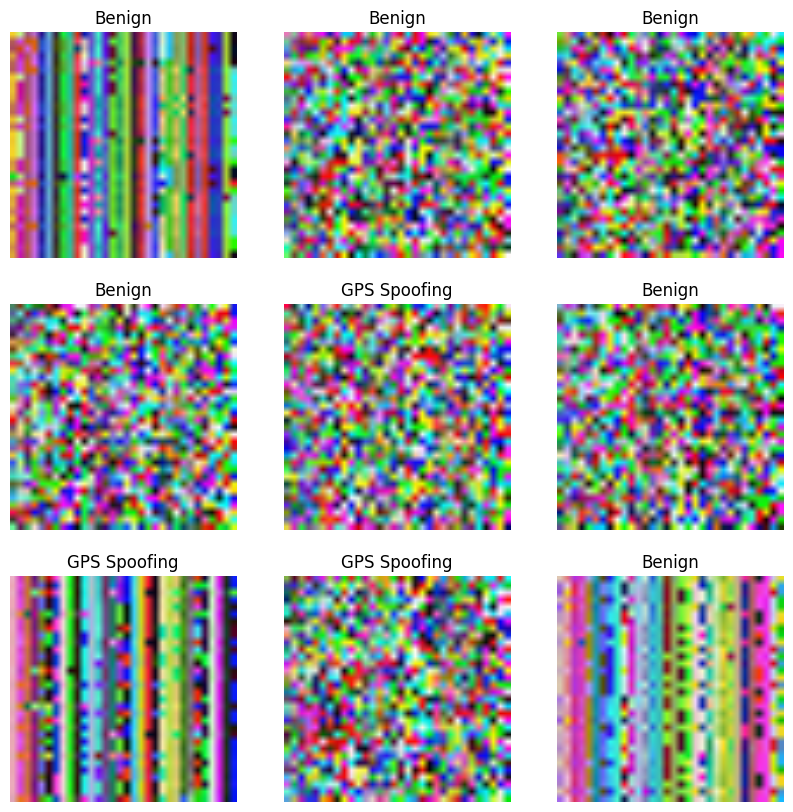

In [295]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions = []
all_label = []

for image_batch, label_batch in test_ds.as_numpy_iterator():
    predictions = model_MobileNetV2.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions.append(predictions)
    all_label.append(label_batch)
    
all_predictions = np.concatenate(all_predictions)
all_label = np.concatenate(all_label)
print('Predictions:\n', all_predictions)
print('Label:\n', all_label)
report = classification_report(all_label , all_predictions, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions[i]])
    plt.axis("off")

In [296]:
cm=confusion_matrix(all_label ,all_predictions)
TP = np.sum((all_predictions == 1) & (all_label == 1))
FP = np.sum((all_predictions == 1) & (all_label == 0))
FN = np.sum((all_predictions == 0) & (all_label == 1))
TN = cm[0, 0]
DA = (TP + TN) / len(all_label)
DP = TP / (TP + FP)
DS = TP / (TP + FN)
DF = 2 * (DP * DS) / (DP + DS)
DE = 1 - DA
FR = FP / (FP + TN)
total_predictions = TP + FP + TN + FN
prediction_overhead = (TP + FP) / total_predictions
TN, FP, FN, TP = confusion_matrix(all_label , all_predictions).ravel()
specificity = TN / (TN + FP)

test_ds (MobileNetV2)
                  
              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99       333
GPS Spoofing       1.00      0.98      0.99       243

    accuracy                           0.99       576
   macro avg       0.99      0.99      0.99       576
weighted avg       0.99      0.99      0.99       576

                  
1) Accuracy: 0.9895833333333334
                  
2) Precision: 0.9897676991150443
                  
3) Recall: 0.9895833333333334
                  
4) Average F1-score: 0.9895647321428572
                  
5) F1-score for each type of attack: [0.99107143 0.9875    ]
                  
6) Average ROC AUC: 0.9876543209876543
                  
7) Average PR AUC: 0.9857253086419753
                  
8) Balanced Accuracy: 0.9876543209876543
                  
9) Hinge: 0.5885416666666666
                  
10) Matthews Correlation Coefficient: 0.9787985196746768
                  
11) Jaccard Score: 0.97

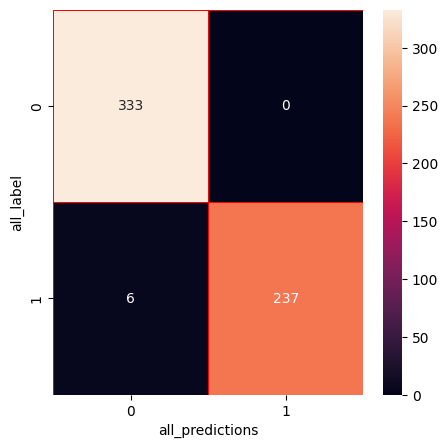

In [297]:
print("test_ds (MobileNetV2)")
print("                  ")
print(report)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_label , all_predictions)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_label , all_predictions, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_label , all_predictions, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_label , all_predictions, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_label , all_predictions, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_label , all_predictions, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_label , all_predictions, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_label , all_predictions)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_label , all_predictions)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_label , all_predictions)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_label , all_predictions)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_label , all_predictions)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_label , all_predictions)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_label ,all_predictions)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions")
plt.ylabel("all_label")
plt.show()

In [298]:
loss_test, accuracy_test = model_MobileNetV2.evaluate(test_ds)
print("test loss: {:.4f}".format(loss_test))
print("test accuracy: {:.4f}".format(accuracy_test))

18/18 [==============================] - 0s 19ms/step - loss: 0.0758 - accuracy: 0.9896
test loss: 0.0758
test accuracy: 0.9896


In [299]:
saved_info = {
    'class_names': class_names,
    'all_label_ResNet50': all_label,
    'all_predictions_ResNet50': all_predictions,
    'cm': cm,
    'accuracy_score': accuracy_score(all_label , all_predictions),
    'precision_score': precision_score(all_label , all_predictions, average='weighted'),
    'recall_score': recall_score(all_label , all_predictions, average='weighted'),
    'f1_score_weighted': f1_score(all_label , all_predictions, average='weighted'),
    'f1_score_each': f1_score(all_label , all_predictions, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_label , all_predictions, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_label , all_predictions, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_label , all_predictions),
    'Hinge': hinge_loss(all_label , all_predictions),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_label , all_predictions),
    'Jaccard Score': jaccard_score(all_label , all_predictions),
    'Log Loss': log_loss(all_label , all_predictions),
    'Zero-One Loss': zero_one_loss(all_label , all_predictions),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('MobileNetV2_test_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [300]:
with open('MobileNetV2_test_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_label_ResNet50'])
print("  ")
print("predictions:", saved_info['all_predictions_ResNet50'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [0 0 0 0 1 0 1 1 0 1 1 1 0 1 1 1 0 1 0 0 0 0 0 1 1 1 1 1 0 1 1 0 1 0 1 0 0
 1 1 1 0 1 1 1 0 0 0 1 1 0 1 1 0 0 1 0 0 0 0 1 1 1 0 1 1 0 0 0 1 0 1 0 0 0
 0 1 0 0 1 1 0 1 0 1 0 1 0 1 0 0 1 0 0 1 0 1 0 1 0 0 1 1 1 1 1 1 0 0 0 0 0
 0 0 0 1 1 0 0 0 1 1 1 1 0 1 0 0 1 1 0 0 0 1 0 0 0 1 0 0 1 0 0 1 1 0 0 0 1
 1 0 0 0 0 1 0 0 0 1 1 0 0 0 0 0 0 1 1 1 1 0 0 0 1 1 1 1 0 1 0 1 0 1 0 0 1
 1 1 1 0 0 1 1 0 0 0 1 0 0 0 1 1 1 0 1 1 0 1 0 0 1 1 0 1 0 1 0 1 0 0 1 0 0
 1 0 1 0 1 0 0 0 0 0 0 0 1 1 0 0 0 1 0 0 0 1 1 0 1 0 1 0 0 0 0 1 0 0 1 0 0
 0 1 1 0 0 0 0 1 0 1 1 0 0 1 1 0 0 1 1 0 0 0 1 0 1 1 0 0 0 1 1 1 0 0 1 0 1
 0 1 1 0 1 0 1 1 0 1 1 0 0 0 1 0 0 1 0 1 1 0 1 0 1 0 1 0 0 0 0 1 0 1 0 0 0
 0 0 0 0 1 0 0 1 0 1 1 1 1 0 1 0 0 1 0 1 0 0 0 1 0 1 1 0 0 1 0 1 1 0 0 0 0
 0 0 0 0 1 1 0 0 1 0 1 0 0 0 0 0 1 1 1 1 0 0 1 1 1 0 1 0 0 0 1 0 0 0 1 1 0
 0 0 1 0 0 0 0 1 0 0 0 0 0 0 1 0 1 1 1 0 0 1 0 0 1 0 1 0 0 1 0 0 0 0 0 0 1
 1 0 1 1 1 1 1 0 0 0 1 1 1 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 1

## Val_ds (MobileNetV2)

Predictions:
 [0 0 0 ... 0 1 1]
Label:
 [0 0 0 ... 0 1 1]


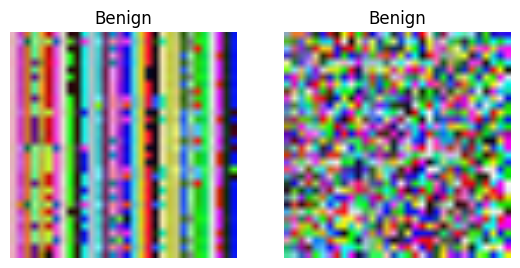

In [301]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions = []
all_label = []

for image_batch, label_batch in val_ds.as_numpy_iterator():
    predictions = model_MobileNetV2.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions.append(predictions)
    all_label.append(label_batch)

all_predictions = np.concatenate(all_predictions)
all_label = np.concatenate(all_label)
print('Predictions:\n', all_predictions)
print('Label:\n', all_label)

report = classification_report(all_label , all_predictions, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions[i]])
    plt.axis("off")

val_ds (MobileNetV2)
                  
              precision    recall  f1-score   support

      Benign       0.97      1.00      0.99       656
GPS Spoofing       1.00      0.96      0.98       470

    accuracy                           0.98      1126
   macro avg       0.99      0.98      0.98      1126
weighted avg       0.98      0.98      0.98      1126

                  
1) Accuracy: 0.9831261101243339
                  
2) Precision: 0.9836010788763897
                  
3) Recall: 0.9831261101243339
                  
4) Average F1-score: 0.98307249528773
                  
5) F1-score for each type of attack: [0.98572502 0.97937025]
                  
6) Average ROC AUC: 0.9797872340425532
                  
7) Average PR AUC: 0.9764483579607725
                  
8) Balanced Accuracy: 0.9797872340425532
                  
9) Hinge: 0.5994671403197158
                  
10) Matthews Correlation Coefficient: 0.9656936490410747
                  
11) Jaccard Score: 0.95957

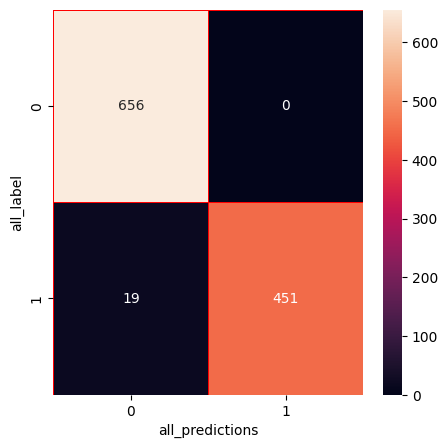

In [302]:
print("val_ds (MobileNetV2)")
print("                  ")
print(report)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_label , all_predictions)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_label , all_predictions, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_label , all_predictions, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_label , all_predictions, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_label , all_predictions, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_label , all_predictions, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_label , all_predictions, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_label , all_predictions)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_label , all_predictions)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_label , all_predictions)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_label , all_predictions)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_label , all_predictions)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_label , all_predictions)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_label ,all_predictions)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions")
plt.ylabel("all_label")
plt.show()

In [303]:
loss_val, accuracy_val = model_MobileNetV2.evaluate(val_ds) 
print("Validation loss: {:.4f}".format(loss_val))
print("Validation Accuracy: {:.4f}".format(accuracy_val))

36/36 [==============================] - 1s 19ms/step - loss: 0.0805 - accuracy: 0.9849
Validation loss: 0.0805
Validation Accuracy: 0.9849


In [304]:
saved_info = {
    'class_names': class_names,
    'all_label': all_label,
    'all_predictions': all_predictions,
    'cm': cm,
    'accuracy_score': accuracy_score(all_label , all_predictions),
    'precision_score': precision_score(all_label , all_predictions, average='weighted'),
    'recall_score': recall_score(all_label , all_predictions, average='weighted'),
    'f1_score_weighted': f1_score(all_label , all_predictions, average='weighted'),
    'f1_score_each': f1_score(all_label , all_predictions, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_label , all_predictions, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_label , all_predictions, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_label , all_predictions),
    'Hinge': hinge_loss(all_label , all_predictions),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_label , all_predictions),
    'Jaccard Score': jaccard_score(all_label , all_predictions),
    'Log Loss': log_loss(all_label , all_predictions),
    'Zero-One Loss': zero_one_loss(all_label , all_predictions),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('MobileNetV2_val_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [305]:
with open('MobileNetV2_val_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)
    
print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_label'])
print("  ")
print("predictions:", saved_info['all_predictions'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [0 0 0 ... 0 1 1]
  
predictions: [0 0 0 ... 0 1 1]
  
cm: [[656   0]
 [ 19 451]]
  
1) Accuracy: 0.9831261101243339
  
2) Precision: 0.9836010788763897
  
3) Recall: 0.9831261101243339
  
4) Average F1-score: 0.98307249528773
  
5) F1-score for each type of attack: [0.98572502 0.97937025]
  
6) Average ROC AUC: 0.9797872340425532
  
7) Average PR AUC: 0.9764483579607725
  
8) Balanced Accuracy: 1.0
  
9) Hinge: 0.5994671403197158
  
10) Matthews Correlation Coefficient: 0.9656936490410747
  
11) Jaccard Score: 0.9595744680851064
  
12) Log Loss: 0.6081966380046414
  
13) Zero-One Loss: 0.01687388987566607
  
14) Prediction Overhead: 0.4114583333333333
  
15) Specificity: 1.0


## TL (MobileNetV2)

In [306]:
base_model_MobileNetV2.trainable = True
print("Number of layers in the base model: ", len(base_model_MobileNetV2.layers))
fine_tune_at_MobileNetV2 = int((130/151)*len(base_model_MobileNetV2.layers))
for layer in base_model_MobileNetV2.layers[:fine_tune_at_MobileNetV2]:
  layer.trainable = False
print("frozen layers in the base model from layer 1 to ", fine_tune_at_MobileNetV2 )
print("unfrozen layers in the base model from %2d to %3d " % (fine_tune_at_MobileNetV2+1,len(base_model_MobileNetV2.layers)))

Number of layers in the base model:  154
frozen layers in the base model from layer 1 to  132
unfrozen layers in the base model from 133 to 154 


In [307]:
history= LossHistory()
savepath='./MobileNetV2+HPO+TL.h5'
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
saveBestModel = kcallbacks.ModelCheckpoint(filepath=savepath, verbose=1,save_best_only=True, mode='auto')
model_MobileNetV2.compile(loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              optimizer = tf.keras.optimizers.Adam(learning_rate=0.00005/10),
              metrics=['accuracy'])
model_MobileNetV2.summary()
len(model_MobileNetV2.trainable_variables)

Model: "model_12"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_26 (InputLayer)       [(None, 224, 224, 3)]     0         
                                                                 
 sequential (Sequential)     (None, 224, 224, 3)       0         
                                                                 
 tf.math.truediv_12 (TFOpLa  (None, 224, 224, 3)       0         
 mbda)                                                           
                                                                 
 tf.math.subtract_12 (TFOpL  (None, 224, 224, 3)       0         
 ambda)                                                          
                                                                 
 mobilenetv2_1.00_224 (Func  (None, 7, 7, 1280)        2257984   
 tional)                                                         
                                                          

25

In [308]:
%%time
fine_tune_epochs = 5
total_epochs =  initial_epochs + fine_tune_epochs
history_fine_MobileNetV2= model_MobileNetV2.fit(train_ds, epochs=total_epochs, initial_epoch=history_MobileNetV2.epoch[-1],
                         validation_data=val_ds, callbacks=[early_stop, saveBestModel, history])

# Inference (Detection)
start_time = time.time()
detection_results = model_MobileNetV2.predict(val_ds)
end_time = time.time()

detection_time = end_time - start_time

print(f"Detection time: {detection_time} seconds")

Epoch 5/10
213/213 [==============================] - ETA: 0s - loss: 0.0443 - accuracy: 0.9874
Epoch 5: val_loss improved from inf to 0.04572, saving model to ./MobileNetV2+HPO+TL.h5


/usr/local/lib/python3.9/site-packages/keras/src/engine/training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


213/213 [==============================] - 11s 31ms/step - loss: 0.0443 - accuracy: 0.9874 - val_loss: 0.0457 - val_accuracy: 0.9831
Epoch 6/10
211/213 [============================>.] - ETA: 0s - loss: 0.0265 - accuracy: 0.9904
Epoch 6: val_loss did not improve from 0.04572
213/213 [==============================] - 6s 26ms/step - loss: 0.0266 - accuracy: 0.9903 - val_loss: 0.0522 - val_accuracy: 0.9911
Epoch 7/10
211/213 [============================>.] - ETA: 0s - loss: 0.0184 - accuracy: 0.9933
Epoch 7: val_loss improved from 0.04572 to 0.02600, saving model to ./MobileNetV2+HPO+TL.h5
213/213 [==============================] - 6s 27ms/step - loss: 0.0183 - accuracy: 0.9932 - val_loss: 0.0260 - val_accuracy: 0.9867
Epoch 8/10
211/213 [============================>.] - ETA: 0s - loss: 0.0139 - accuracy: 0.9951
Epoch 8: val_loss did not improve from 0.02600
213/213 [==============================] - 6s 26ms/step - loss: 0.0138 - accuracy: 0.9952 - val_loss: 0.0285 - val_accuracy: 0.99

## MobileNetV2 Graph

In [309]:
acc_MobileNetV2 += history_fine_MobileNetV2.history['accuracy']
val_acc_MobileNetV2 += history_fine_MobileNetV2.history['val_accuracy']

loss_MobileNetV2 += history_fine_MobileNetV2.history['loss']
val_loss_MobileNetV2 += history_fine_MobileNetV2.history['val_loss']

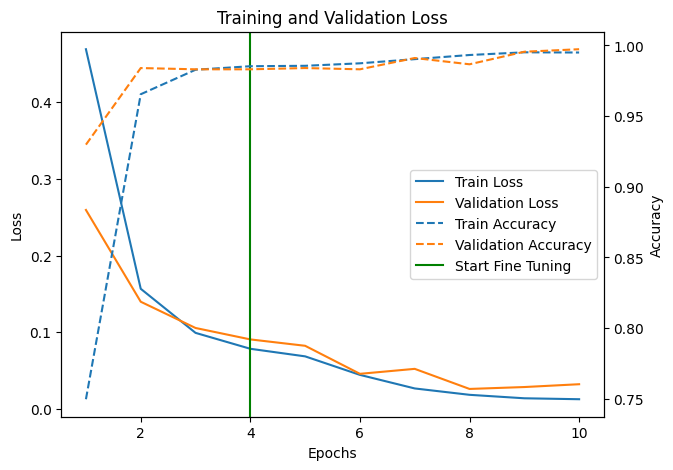

In [310]:
actual_epochs = range(1, total_epochs + 1)  
actual_train_loss = loss_MobileNetV2[:total_epochs]  
actual_val_loss = val_loss_MobileNetV2[:total_epochs]  
actual_train_accuracy = acc_MobileNetV2[:total_epochs]  
actual_val_accuracy = val_acc_MobileNetV2[:total_epochs]

fig, ax1 = plt.subplots(figsize=(7, 5))
ax1.plot(actual_epochs, actual_train_loss, '-', label='Train Loss')
ax1.plot(actual_epochs, actual_val_loss, '-', label='Validation Loss')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.set_title('Training and Validation Loss')
ax2 = ax1.twinx()
ax2.plot(actual_epochs, actual_train_accuracy, '--', label='Train Accuracy')
ax2.plot(actual_epochs, actual_val_accuracy, '--', label='Validation Accuracy')
ax2.set_ylabel('Accuracy')
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
custom_legend_elements = handles1 + handles2 + [plt.Line2D([0], [0], color='green', label='Start Fine Tuning')]
custom_legend_labels = labels1 + labels2 + ['Start Fine Tuning']
ax1.legend(custom_legend_elements, custom_legend_labels, loc='center right')
ax1.axvline(x=initial_epochs - 1, color='green')
plot_data = {'fig': fig, 'ax1': ax1, 'ax2': ax2}

learning_curve_data = {
    'train_loss': actual_train_loss,
    'val_loss': actual_val_loss,
    'train_acc': actual_train_accuracy,
    'val_acc': actual_val_accuracy
}

with open('MobileNetV2+Start Fine Tuning.pkl', 'wb') as file:
    pickle.dump(plot_data, file)
plt.savefig('MobileNetV2+Start Fine Tuning.pdf', format='pdf', dpi=300)
plt.savefig('MobileNetV2+Start Fine Tuning.svg', format='svg')
plt.savefig('MobileNetV2+Start Fine Tuning.png', format='png', dpi=300)
plt.show()

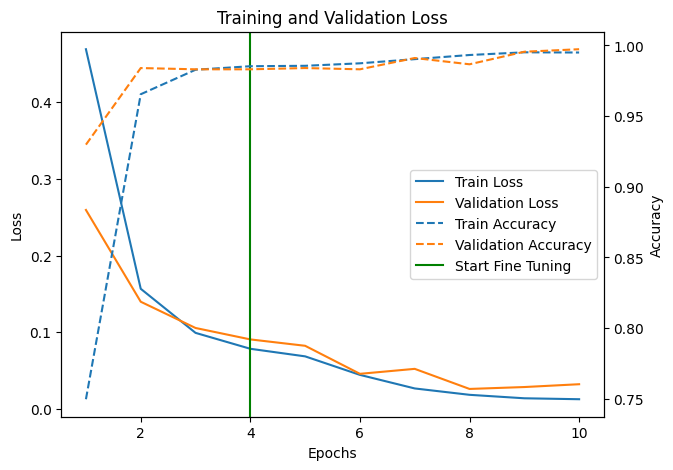

Training Loss: [0.4691024720668793, 0.15663626790046692, 0.09914222359657288, 0.07838127762079239, 0.06849946081638336, 0.044342417269945145, 0.02664964646100998, 0.01834007352590561, 0.013817626051604748, 0.01259229052811861]
Validation Loss: [0.2594543993473053, 0.13974785804748535, 0.10552015155553818, 0.0906023234128952, 0.0822853371500969, 0.04571879655122757, 0.05219985917210579, 0.026004577055573463, 0.028480252251029015, 0.03215394169092178]
Training Accuracy: [0.7497429847717285, 0.9654868841171265, 0.9828168749809265, 0.9853135347366333, 0.9856072664260864, 0.9873696565628052, 0.9903069734573364, 0.9932442307472229, 0.9951534867286682, 0.9950066208839417]
Validation Accuracy: [0.9298401474952698, 0.9840142130851746, 0.9831261038780212, 0.9831261038780212, 0.9840142130851746, 0.9831261038780212, 0.9911190271377563, 0.9866784811019897, 0.9955595135688782, 0.99733567237854]


In [311]:
with open('MobileNetV2+Start Fine Tuning.pkl', 'rb') as file:
    learning_curve = pickle.load(file)
fig = learning_curve['fig']
ax1 = learning_curve['ax1']
ax2 = learning_curve['ax2']
plt.show()
train_loss = learning_curve_data['train_loss']
val_loss = learning_curve_data['val_loss']
train_acc = learning_curve_data['train_acc']
val_acc = learning_curve_data['val_acc']
print("Training Loss:", learning_curve_data['train_loss'])
print("Validation Loss:", learning_curve_data['val_loss'])
print("Training Accuracy:", learning_curve_data['train_acc'])
print("Validation Accuracy:", learning_curve_data['val_acc'])

## Test_ds(MobileNetV2) +TL

Predictions:
 [0 0 1 0 1 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1 1 0 1 1 1 0 1 0 0
 0 0 0 0 1 0 0 0 1 1 0 1 1 1 0 1 0 0 0 1 1 1 1 0 0 1 0 0 1 1 0 0 1 0 1 0 1
 0 0 0 1 0 0 0 0 0 0 1 1 1 1 0 1 0 0 1 0 0 1 1 1 0 0 1 1 0 1 0 1 0 0 1 1 1
 0 0 0 1 1 0 1 1 1 1 1 0 0 0 0 0 1 1 1 1 0 0 0 1 0 1 0 0 0 1 1 1 0 0 0 0 0
 0 1 0 1 1 0 0 1 0 1 1 1 1 1 1 1 1 1 0 0 0 0 0 1 0 1 0 0 1 0 1 1 0 1 0 1 1
 0 1 0 0 0 0 0 1 1 0 1 0 0 0 0 0 0 1 1 1 0 0 0 0 1 0 0 1 0 1 0 1 0 0 1 0 1
 0 0 0 0 0 0 1 1 1 1 1 0 0 1 0 1 1 0 1 0 0 1 0 1 1 0 0 0 0 1 1 1 1 1 0 0 1
 0 0 1 0 0 0 0 0 0 0 0 1 1 1 1 0 0 1 0 1 0 0 0 0 1 1 0 0 0 0 0 0 0 1 1 0 1
 1 1 0 0 1 0 1 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0 1 0 1 1 1 1 0 1 1 1 1 0 1 0 0
 0 0 0 0 0 1 0 0 0 0 0 1 0 0 1 1 1 1 1 0 1 1 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0
 1 1 0 0 1 1 1 0 0 1 0 0 0 0 0 1 0 1 1 0 1 0 0 0 1 0 0 0 0 0 0 1 1 0 1 1 1
 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 1 0 0 1 0 1 1 1 1 1 0 0 1 1 1 1 0 1 1 0 0
 0 1 0 0 0 1 1 0 0 1 1 0 1 1 0 0 1 0 0 1 0 0 1 0 1 0 1 1 1 0 1 1 0 0 1 0 0
 0 1 1 0 0 

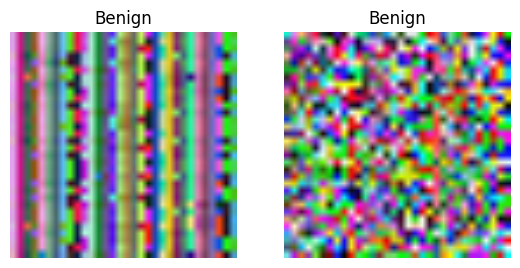

In [312]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions = []
all_label = []

for image_batch, label_batch in test_ds.as_numpy_iterator():
    predictions = model_MobileNetV2.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions.append(predictions)
    all_label.append(label_batch)
    
all_predictions = np.concatenate(all_predictions)
all_label = np.concatenate(all_label)
print('Predictions:\n', all_predictions)
print('Labels:\n', all_label)
report_MobileNetV2 = classification_report(all_label , all_predictions, target_names=class_names_s)

plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions[i]])
    plt.axis("off")

test_ds (MobileNetV2)
                  
              precision    recall  f1-score   support

      Benign       0.97      1.00      0.99       656
GPS Spoofing       1.00      0.96      0.98       470

    accuracy                           0.98      1126
   macro avg       0.99      0.98      0.98      1126
weighted avg       0.98      0.98      0.98      1126

                  
1) Accuracy: 1.0
                  
2) Precision: 1.0
                  
3) Recall: 1.0
                  
4) Average F1-score: 1.0
                  
5) F1-score for each type of attack: [1. 1.]
                  
6) Average ROC AUC: 1.0
                  
7) Average PR AUC: 1.0
                  
8) Balanced Accuracy: 1.0
                  
9) Hinge: 0.5833333333333334
                  
10) Matthews Correlation Coefficient: 1.0
                  
11) Jaccard Score: 1.0
                  
12) Log Loss: 2.2204460492503136e-16
                  
13) Zero-One Loss 0.0
                  
14) Prediction Overh

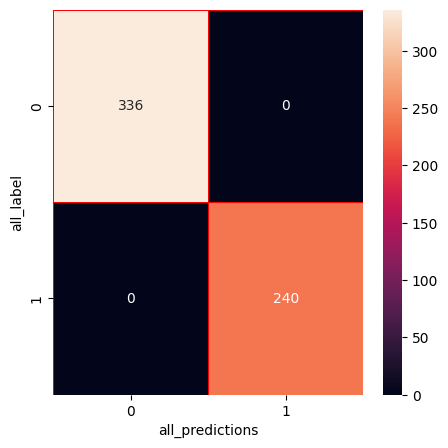

In [313]:
print("test_ds (MobileNetV2)")
print("                  ")
print(report)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_label , all_predictions)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_label , all_predictions, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_label , all_predictions, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_label , all_predictions, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_label , all_predictions, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_label , all_predictions, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_label , all_predictions, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_label , all_predictions)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_label , all_predictions)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_label , all_predictions)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_label , all_predictions)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_label , all_predictions)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_label , all_predictions)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_label ,all_predictions)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions")
plt.ylabel("all_label")
plt.show()

In [314]:
loss_test_MobileNetV2, accuracy_test_MobileNetV2 = model_MobileNetV2.evaluate(test_ds)
print("Test Loss: {:.3f}".format(loss_test_MobileNetV2))
print("Test Accuracy: {:.3f}".format(accuracy_test_MobileNetV2))

18/18 [==============================] - 0s 20ms/step - loss: 0.0329 - accuracy: 1.0000
Test Loss: 0.033
Test Accuracy: 1.000


In [315]:
saved_info = {
    'class_names': class_names,
    'all_label': all_label,
    'all_predictions': all_predictions,
    'cm': cm,
    'accuracy_score': accuracy_score(all_label , all_predictions),
    'precision_score': precision_score(all_label , all_predictions, average='weighted'),
    'recall_score': recall_score(all_label , all_predictions, average='weighted'),
    'f1_score_weighted': f1_score(all_label , all_predictions, average='weighted'),
    'f1_score_each': f1_score(all_label , all_predictions, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_label , all_predictions, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_label , all_predictions, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_label , all_predictions),
    'Hinge': hinge_loss(all_label , all_predictions),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_label , all_predictions),
    'Jaccard Score': jaccard_score(all_label , all_predictions),
    'Log Loss': log_loss(all_label , all_predictions),
    'Zero-One Loss': zero_one_loss(all_label , all_predictions),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('MobileNetV2_test(TL)_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [316]:
#=========

In [317]:
with open('MobileNetV2_test(TL)_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)
    
print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_label'])
print("  ")
print("predictions:", saved_info['all_predictions'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [0 0 1 0 1 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1 1 0 1 1 1 0 1 0 0
 0 0 0 0 1 0 0 0 1 1 0 1 1 1 0 1 0 0 0 1 1 1 1 0 0 1 0 0 1 1 0 0 1 0 1 0 1
 0 0 0 1 0 0 0 0 0 0 1 1 1 1 0 1 0 0 1 0 0 1 1 1 0 0 1 1 0 1 0 1 0 0 1 1 1
 0 0 0 1 1 0 1 1 1 1 1 0 0 0 0 0 1 1 1 1 0 0 0 1 0 1 0 0 0 1 1 1 0 0 0 0 0
 0 1 0 1 1 0 0 1 0 1 1 1 1 1 1 1 1 1 0 0 0 0 0 1 0 1 0 0 1 0 1 1 0 1 0 1 1
 0 1 0 0 0 0 0 1 1 0 1 0 0 0 0 0 0 1 1 1 0 0 0 0 1 0 0 1 0 1 0 1 0 0 1 0 1
 0 0 0 0 0 0 1 1 1 1 1 0 0 1 0 1 1 0 1 0 0 1 0 1 1 0 0 0 0 1 1 1 1 1 0 0 1
 0 0 1 0 0 0 0 0 0 0 0 1 1 1 1 0 0 1 0 1 0 0 0 0 1 1 0 0 0 0 0 0 0 1 1 0 1
 1 1 0 0 1 0 1 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0 1 0 1 1 1 1 0 1 1 1 1 0 1 0 0
 0 0 0 0 0 1 0 0 0 0 0 1 0 0 1 1 1 1 1 0 1 1 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0
 1 1 0 0 1 1 1 0 0 1 0 0 0 0 0 1 0 1 1 0 1 0 0 0 1 0 0 0 0 0 0 1 1 0 1 1 1
 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 1 0 0 1 0 1 1 1 1 1 0 0 1 1 1 1 0 1 1 0 0
 0 1 0 0 0 1 1 0 0 1 1 0 1 1 0 0 1 0 0 1 0 0 1 0 1 0 1 1 1 0 1 1 0

## Val_ds + TL (MobileNetV2)

Predictions:
 [0 0 1 ... 0 1 0]
Labels:
 [0 0 1 ... 0 1 0]


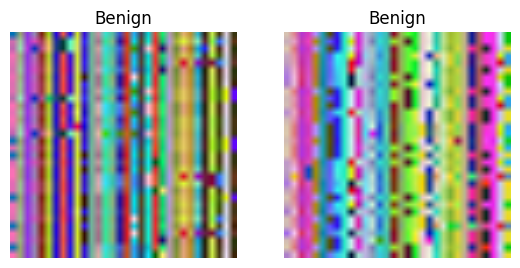

In [318]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions = []
all_label = []

for image_batch, label_batch in val_ds.as_numpy_iterator():
    predictions = model_MobileNetV2.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions.append(predictions)
    all_label.append(label_batch)
    
all_predictions = np.concatenate(all_predictions)
all_label = np.concatenate(all_label)
print('Predictions:\n', all_predictions)
print('Labels:\n', all_label)

report_MobileNetV2 = classification_report(all_label , all_predictions, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions[i]])
    plt.axis("off")

val_ds (MobileNetV2) + TL
                  
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00       635
GPS Spoofing       0.99      1.00      1.00       491

    accuracy                           1.00      1126
   macro avg       1.00      1.00      1.00      1126
weighted avg       1.00      1.00      1.00      1126

                  
1) Accuracy: 0.9973357015985791
                  
2) Precision: 0.9973518815483852
                  
3) Recall: 0.9973357015985791
                  
4) Average F1-score: 0.9973366046456456
                  
5) F1-score for each type of attack: [0.9976322  0.99695431]
                  
6) Average ROC AUC: 0.9976377952755905
                  
7) Average PR AUC: 0.9939271255060729
                  
8) Balanced Accuracy: 0.9976377952755906
                  
9) Hinge: 0.566607460035524
                  
10) Matthews Correlation Coefficient: 0.9946011295001099
                  
11) Jaccard Score: 0

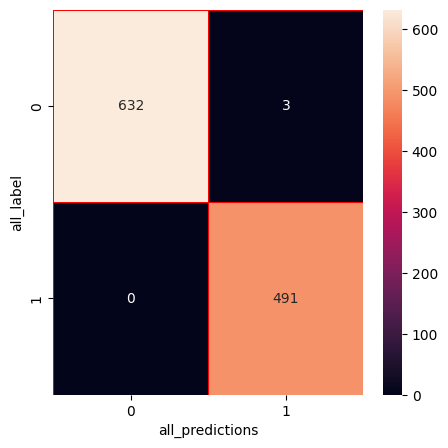

In [319]:
print("val_ds (MobileNetV2) + TL")
print("                  ")
print(report_MobileNetV2)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_label , all_predictions)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_label , all_predictions, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_label , all_predictions, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_label , all_predictions, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_label , all_predictions, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_label , all_predictions, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_label , all_predictions, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_label , all_predictions)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_label , all_predictions)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_label , all_predictions)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_label , all_predictions)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_label , all_predictions)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_label , all_predictions)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_label ,all_predictions)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions")
plt.ylabel("all_label")
plt.show()

In [320]:
loss_val_MobileNetV2, accuracy_val_MobileNetV2 = model_MobileNetV2.evaluate(val_ds)
print("Validation Loss: {:.3f}".format(loss_val_MobileNetV2))
print("Validation Accuracy: {:.3f}".format(accuracy_val_MobileNetV2))

36/36 [==============================] - 1s 19ms/step - loss: 0.0347 - accuracy: 0.9982
Validation Loss: 0.035
Validation Accuracy: 0.998


In [321]:
saved_info = {
    'class_names': class_names,
    'all_label': all_label,
    'all_predictions': all_predictions,
    'cm': cm,
    'accuracy_score': accuracy_score(all_label , all_predictions),
    'precision_score': precision_score(all_label , all_predictions, average='weighted'),
    'recall_score': recall_score(all_label , all_predictions, average='weighted'),
    'f1_score_weighted': f1_score(all_label , all_predictions, average='weighted'),
    'f1_score_each': f1_score(all_label , all_predictions, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_label , all_predictions, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_label , all_predictions, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_label , all_predictions),
    'Hinge': hinge_loss(all_label , all_predictions),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_label , all_predictions),
    'Jaccard Score': jaccard_score(all_label , all_predictions),
    'Log Loss': log_loss(all_label , all_predictions),
    'Zero-One Loss': zero_one_loss(all_label , all_predictions),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}
with open('MobileNetV2_Val(TL)_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [322]:
#=========

In [323]:
with open('MobileNetV2_Val(TL)_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_label'])
print("  ")
print("predictions:", saved_info['all_predictions'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])
print("  ")

Class Names: ['0', '1']
  
Label: [0 0 1 ... 0 1 0]
  
predictions: [0 0 1 ... 0 1 0]
  
cm: [[632   3]
 [  0 491]]
  
1) Accuracy: 0.9973357015985791
  
2) Precision: 0.9973518815483852
  
3) Recall: 0.9973357015985791
  
4) Average F1-score: 0.9973366046456456
  
5) F1-score for each type of attack: [0.9976322  0.99695431]
  
6) Average ROC AUC: 0.9976377952755905
  
7) Average PR AUC: 0.9939271255060729
  
8) Balanced Accuracy: 1.0
  
9) Hinge: 0.566607460035524
  
10) Matthews Correlation Coefficient: 0.9946011295001099
  
11) Jaccard Score: 0.9939271255060729
  
12) Log Loss: 0.09603104810599618
  
13) Zero-One Loss: 0.002664298401420906
  
14) Prediction Overhead: 0.4114583333333333
  
15) Specificity: 1.0
  


## Load the saved model and Learning curve

In [324]:
new_model = tf.keras.models.load_model('./MobileNetV2+TL.h5')

In [325]:
for layer in new_model.layers:
    print(layer.name)
    weights = layer.get_weights()
    
    for weight in weights:
        print(weight)

input_4
sequential
tf.math.truediv
tf.math.subtract
mobilenetv2_1.00_224
[[[[-1.71659231e-01 -3.33731920e-01  5.30122258e-02 -5.93232973e-21
     2.08742931e-01 -1.20433941e-01  1.75700430e-02 -3.10708203e-22
    -9.62498877e-03  1.90229788e-01 -3.67278278e-01  3.95997976e-22
    -2.36236629e-22  3.36706383e-22  8.83555040e-02 -7.75416642e-02
     3.95842289e-05 -3.63377742e-02  5.99925742e-02  5.53736472e-21
    -4.68022423e-04 -1.23387486e-01 -1.34351701e-01  8.75968020e-03
    -2.47503355e-01  1.58492010e-02 -2.43145856e-04 -1.09811597e-01
     5.55126644e-22 -2.03368161e-03  2.83311605e-01  7.66634047e-02]
   [-3.18941772e-01 -6.09864295e-01 -1.70770675e-01 -6.76705635e-21
    -5.82342505e-01 -2.56068230e-01 -4.18974347e-02  1.32427304e-22
     2.00757684e-04  3.29488933e-01 -4.01886106e-01  3.63034420e-22
     1.64733595e-22  1.97648923e-22  9.94425565e-02 -1.17755957e-01
     5.50664954e-05 -5.31860851e-02 -2.15648204e-01  3.16011650e-21
     8.09127018e-02  7.85512850e-02 -2.842

In [326]:
print(new_model.get_config())

{'name': 'model_1', 'trainable': True, 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_input_shape': (None, 224, 224, 3), 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'input_4'}, 'registered_name': None, 'name': 'input_4', 'inbound_nodes': []}, {'module': 'keras', 'class_name': 'Sequential', 'config': {'name': 'sequential', 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_input_shape': (None, 224, 224, 3), 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'random_flip_input'}, 'registered_name': None}, {'module': 'keras.layers', 'class_name': 'RandomFlip', 'config': {'name': 'random_flip', 'trainable': True, 'dtype': 'float32', 'mode': 'horizontal_and_vertical', 'seed': None}, 'registered_name': None, 'build_config': {'input_shape': (None, 224, 224, 3)}}, {'module': 'keras.layers', 'class_name': 'RandomRotation', 'config': {'name': 'random_rotation', 'trainable': True, 'dtype': 'float32'

# Xception model

In [103]:
IMG_SHAPE = (img_height, img_width,3)
base_model_Xception = tf.keras.applications.Xception(input_shape=IMG_SHAPE,
                                               include_top=False,   
                                               weights='imagenet')

In [104]:
base_model_Xception.trainable = False
base_model_Xception.summary()

Model: "xception"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_5 (InputLayer)        [(None, 224, 224, 3)]        0         []                            
                                                                                                  
 block1_conv1 (Conv2D)       (None, 111, 111, 32)         864       ['input_5[0][0]']             
                                                                                                  
 block1_conv1_bn (BatchNorm  (None, 111, 111, 32)         128       ['block1_conv1[0][0]']        
 alization)                                                                                       
                                                                                                  
 block1_conv1_act (Activati  (None, 111, 111, 32)         0         ['block1_conv1_bn[0][0]

 block9_sepconv3_bn (BatchNorma  (None, 14, 14, 728)  2912       ['block9_sepconv3[0][0]']        
 lization)                                                                                        
                                                                                                  
 add_7 (Add)                    (None, 14, 14, 728)  0           ['block9_sepconv3_bn[0][0]',     
                                                                  'add_6[0][0]']                  
                                                                                                  
 block10_sepconv1_act (Activati  (None, 14, 14, 728)  0          ['add_7[0][0]']                  
 on)                                                                                              
                                                                                                  
 block10_sepconv1 (SeparableCon  (None, 14, 14, 728)  536536     ['block10_sepconv1_act[0][0]']   
 v2D)     

                                                                                                  
 block12_sepconv3_act (Activati  (None, 14, 14, 728)  0          ['block12_sepconv2_bn[0][0]']    
 on)                                                                                              
                                                                                                  
 block12_sepconv3 (SeparableCon  (None, 14, 14, 728)  536536     ['block12_sepconv3_act[0][0]']   
 v2D)                                                                                             
                                                                                                  
 block12_sepconv3_bn (BatchNorm  (None, 14, 14, 728)  2912       ['block12_sepconv3[0][0]']       
 alization)                                                                                       
                                                                                                  
 add_10 (A

In [105]:
image_batch, label_batch = next(iter(train_ds))
feature_batch_Xception = base_model_Xception(image_batch)
print(feature_batch_Xception.shape)
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
feature_batch_average_Xception = global_average_layer(feature_batch_Xception)
print(feature_batch_average_Xception.shape)
prediction_layer_Xception = tf.keras.layers.Dense(1)
prediction_batch_Xception = prediction_layer_Xception(feature_batch_average_Xception)
print(prediction_batch_Xception.shape)

(32, 7, 7, 2048)
(32, 2048)
(32, 1)


In [106]:
inputs_Xception = tf.keras.Input(shape=(img_height, img_width,3))
x_Xception = data_augmentation(inputs_Xception) 
x_Xception = tf.keras.applications.xception.preprocess_input (x_Xception)  
x_Xception = base_model_Xception(x_Xception, training=False)
x_Xception = global_average_layer(x_Xception)  
x_Xception = tf.keras.layers.Dropout(0.2)(x_Xception)  
outputs_Xception = prediction_layer_Xception(x_Xception) 
model_Xception = tf.keras.Model(inputs_Xception, outputs_Xception)

In [107]:
class LossHistory(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs={}):
        self.losses = {'batch':[], 'epoch':[]}
        self.accuracy = {'batch':[], 'epoch':[]}
        self.val_loss = {'batch':[], 'epoch':[]}
        self.val_acc = {'batch':[], 'epoch':[]}
        self.history = {}
    def on_batch_end(self, batch, logs={}):
        self.losses['batch'].append(logs.get('loss'))
        self.accuracy['batch'].append(logs.get('accuracy'))
        self.val_loss['batch'].append(logs.get('val_loss'))
        self.val_acc['batch'].append(logs.get('val_accuracy'))
    def on_epoch_end(self, batch, logs={}):
        self.losses['epoch'].append(logs.get('loss'))
        self.accuracy['epoch'].append(logs.get('accuracy'))
        self.val_loss['epoch'].append(logs.get('val_loss'))
        self.val_acc['epoch'].append(logs.get('val_accuracy'))
        self.history = {'loss': self.losses, 'accuracy': self.accuracy, 'val_loss': self.val_loss, 'val_accuracy': self.val_acc}

In [108]:
history= LossHistory()
base_learning_rate = 0.00007
savepath='./Xception.h5'
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
saveBestModel = kcallbacks.ModelCheckpoint(filepath=savepath, verbose=1, save_best_only=True, mode='auto')
model_Xception.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
              loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [109]:
model_Xception.summary()

Model: "model_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_6 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 sequential (Sequential)     (None, 224, 224, 3)       0         
                                                                 
 tf.math.truediv_1 (TFOpLam  (None, 224, 224, 3)       0         
 bda)                                                            
                                                                 
 tf.math.subtract_1 (TFOpLa  (None, 224, 224, 3)       0         
 mbda)                                                           
                                                                 
 xception (Functional)       (None, 7, 7, 2048)        20861480  
                                                                 
 global_average_pooling2d_2  (None, 2048)              0   

In [110]:
initial_epochs = 5
loss0, accuracy0 = model_Xception.evaluate(val_ds)

36/36 [==============================] - 6s 70ms/step - loss: 0.6296 - accuracy: 0.5737


In [111]:
print("initial loss: {:.4f}".format(loss0))
print("initial accuracy: {:.4f}".format(accuracy0))

initial loss: 0.6296
initial accuracy: 0.5737


In [112]:
%%time
history_Xception = model_Xception.fit(train_ds, epochs=initial_epochs, validation_data=val_ds, 
                                      callbacks=[early_stop, saveBestModel, history])

# Inference (Detection)
start_time = time.time()
detection_results = model_Xception.predict(val_ds)
end_time = time.time()

detection_time = end_time - start_time

print(f"Detection time: {detection_time} seconds")

Epoch 1/5
212/213 [============================>.] - ETA: 0s - loss: 0.3789 - accuracy: 0.8136
Epoch 1: val_loss improved from inf to 0.21480, saving model to ./Xception.h5


/usr/local/lib/python3.9/site-packages/keras/src/engine/training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


213/213 [==============================] - 16s 66ms/step - loss: 0.3779 - accuracy: 0.8145 - val_loss: 0.2148 - val_accuracy: 0.9849
Epoch 2/5
213/213 [==============================] - ETA: 0s - loss: 0.1549 - accuracy: 0.9836
Epoch 2: val_loss improved from 0.21480 to 0.12529, saving model to ./Xception.h5
213/213 [==============================] - 13s 63ms/step - loss: 0.1549 - accuracy: 0.9836 - val_loss: 0.1253 - val_accuracy: 0.9822
Epoch 3/5
213/213 [==============================] - ETA: 0s - loss: 0.0980 - accuracy: 0.9852
Epoch 3: val_loss improved from 0.12529 to 0.09205, saving model to ./Xception.h5
213/213 [==============================] - 13s 61ms/step - loss: 0.0980 - accuracy: 0.9852 - val_loss: 0.0921 - val_accuracy: 0.9831
Epoch 4/5
213/213 [==============================] - ETA: 0s - loss: 0.0764 - accuracy: 0.9860
Epoch 4: val_loss improved from 0.09205 to 0.07415, saving model to ./Xception.h5
213/213 [==============================] - 12s 59ms/step - loss: 0.076

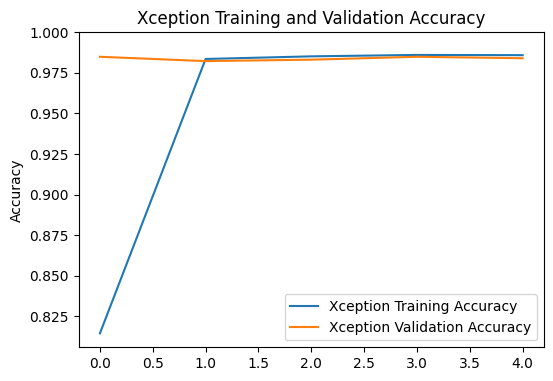

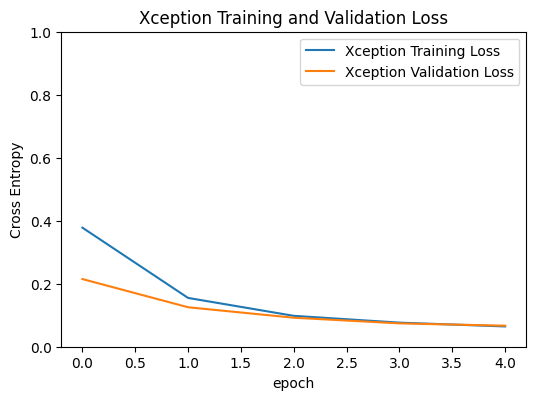

In [113]:
acc_Xception = history_Xception.history['accuracy']
val_acc_Xception = history_Xception.history['val_accuracy']
loss_Xception = history_Xception.history['loss']
val_loss_Xception = history_Xception.history['val_loss']

plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 1)
plt.plot(acc_Xception, label='Xception Training Accuracy')
plt.plot(val_acc_Xception, label='Xception Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),1])
plt.title('Xception Training and Validation Accuracy')
plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 2)
plt.plot(loss_Xception, label='Xception Training Loss')
plt.plot(val_loss_Xception, label='Xception Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0,1.0])
plt.title('Xception Training and Validation Loss')
plt.xlabel('epoch')

plt.savefig('Xception_Full.pdf', format='pdf', dpi=300)
plt.savefig('Xception_Full.svg', format='svg')
plt.savefig('Xception_Full.png', format='png', dpi=300)
plt.show()

## Test_ds (Xception)

Predictions:
 [0 0 1 1 0 0 1 1 1 0 1 0 1 1 0 0 0 0 1 1 0 0 1 0 1 1 0 0 0 1 0 1 1 1 1 0 0
 0 1 1 0 0 0 0 0 0 0 0 0 0 1 1 0 1 1 0 1 0 1 0 0 1 1 1 0 0 0 0 0 0 1 1 1 0
 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 1 0 0 1 0 0 0 0 1 0 1 1 0 0 1 0 1 1 0
 0 1 0 0 1 0 0 0 0 0 1 0 0 0 1 1 0 1 1 0 1 0 1 1 0 1 1 0 0 0 1 0 0 1 0 0 1
 1 0 0 1 0 0 0 0 1 0 1 1 0 0 1 1 0 1 1 1 0 1 1 0 1 0 1 0 1 0 1 1 0 0 0 0 0
 1 0 0 1 1 1 0 0 0 0 1 0 1 1 1 0 0 0 1 1 1 0 1 0 1 1 0 0 0 0 0 1 0 1 1 1 0
 1 1 1 1 0 1 0 0 0 0 1 1 0 1 0 0 1 0 0 0 1 1 0 0 1 0 1 0 0 1 1 0 0 0 1 0 0
 1 0 1 1 1 1 1 1 0 1 1 0 1 0 0 0 0 1 0 0 0 1 0 0 0 1 0 0 1 1 0 0 1 0 1 0 1
 1 0 1 0 0 0 0 1 1 0 0 0 1 0 1 0 0 1 0 1 0 1 0 0 1 0 0 0 1 1 0 0 0 0 0 0 1
 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 1 0 0 0 1 1 1 1 1 0
 0 0 1 1 0 1 0 0 1 0 1 1 0 0 0 1 0 1 1 0 0 1 0 1 0 0 0 1 0 0 1 1 0 0 1 0 1
 0 1 0 1 1 1 0 0 1 0 0 0 1 1 0 1 1 0 1 0 0 1 0 1 1 0 0 1 0 0 1 0 0 1 1 1 1
 0 0 1 1 1 0 0 0 1 1 0 0 0 1 0 1 0 0 1 1 0 0 0 1 0 1 1 0 0 1 0 0 1 1 0 0 0
 0 0 0 0 0 

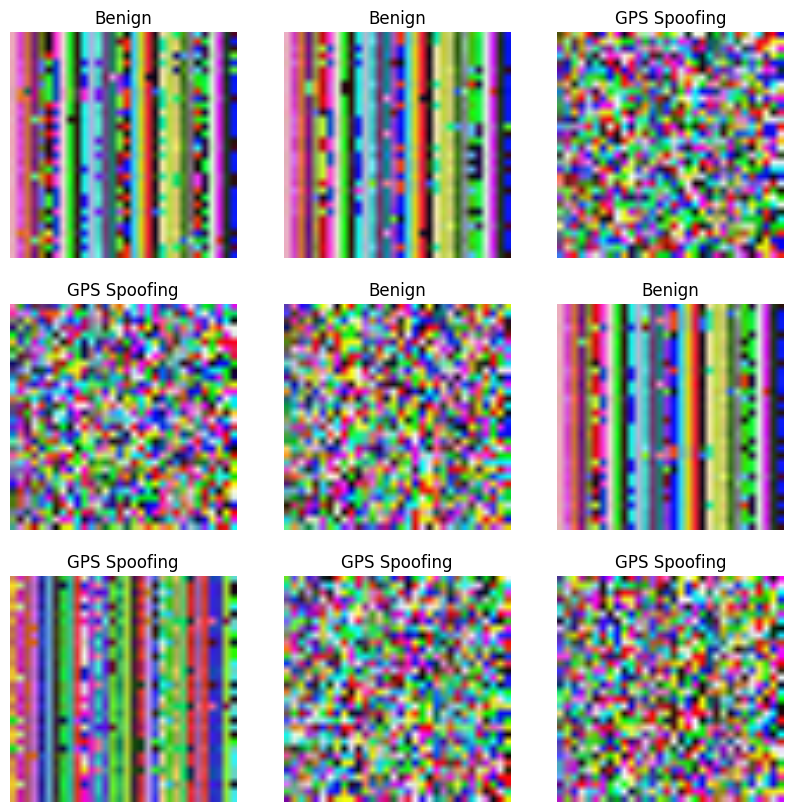

In [114]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_Xception = []
all_labels_Xception = []

for image_batch, label_batch in test_ds.as_numpy_iterator():
    predictions = model_Xception.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_Xception.append(predictions)
    all_labels_Xception.append(label_batch)
    
all_predictions_Xception = np.concatenate(all_predictions_Xception)
all_labels_Xception = np.concatenate(all_labels_Xception)
print('Predictions:\n', all_predictions_Xception)
print('Labels:\n', all_labels_Xception)
report_Xception = classification_report(all_labels_Xception, all_predictions_Xception, target_names=class_names_s)

plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_Xception[i]])
    plt.axis("off")

In [115]:
cm=confusion_matrix(all_labels_Xception ,all_predictions_Xception)
TP = np.sum((all_predictions_Xception == 1) & (all_labels_Xception == 1))
FP = np.sum((all_predictions_Xception == 1) & (all_labels_Xception == 0))
FN = np.sum((all_predictions_Xception == 0) & (all_labels_Xception == 1))
TN = cm[0, 0]
DA = (TP + TN) / len(all_labels_Xception)
DP = TP / (TP + FP)
DS = TP / (TP + FN)
DF = 2 * (DP * DS) / (DP + DS)
DE = 1 - DA
FR = FP / (FP + TN)
total_predictions = TP + FP + TN + FN
prediction_overhead = (TP + FP) / total_predictions
TN, FP, FN, TP = confusion_matrix(all_labels_Xception, all_predictions_Xception).ravel()
specificity = TN / (TN + FP)

test_ds (Xception)
                  
              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99       322
GPS Spoofing       1.00      0.98      0.99       254

    accuracy                           0.99       576
   macro avg       0.99      0.99      0.99       576
weighted avg       0.99      0.99      0.99       576

                  
1) Accuracy: 0.9895833333333334
                  
2) Precision: 0.9897738821138211
                  
3) Recall: 0.9895833333333334
                  
4) Average F1-score: 0.9895691592603941
                  
5) F1-score for each type of attack: [0.99076923 0.98804781]
                  
6) Average ROC AUC: 0.9881889763779528
                  
7) Average PR AUC: 0.9867946194225722
                  
8) Balanced Accuracy: 0.9881889763779528
                  
9) Hinge: 0.5694444444444444
                  
10) Matthews Correlation Coefficient: 0.979039008645414
                  
11) Jaccard Score: 0.976377

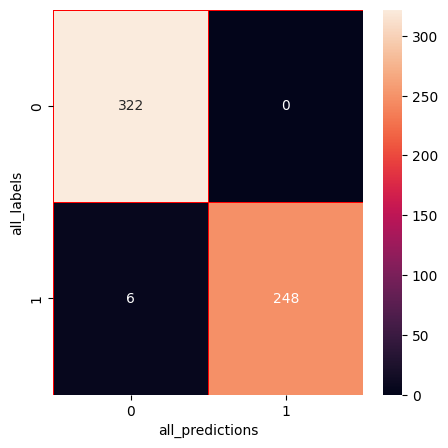

In [116]:
print("test_ds (Xception)")
print("                  ")
print(report_Xception)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_Xception , all_predictions_Xception, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_Xception , all_predictions_Xception, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_Xception , all_predictions_Xception, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_Xception , all_predictions_Xception, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_Xception , all_predictions_Xception, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_Xception , all_predictions_Xception, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_Xception ,all_predictions_Xception)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions")
plt.ylabel("all_labels")
plt.show()

In [117]:
loss_test_Xception, accuracy_test_Xception = model_Xception.evaluate(test_ds)
print("test loss_Xception: {:.4f}".format(loss_test_Xception))
print("test accuracy_Xception: {:.4f}".format(accuracy_test_Xception))

18/18 [==============================] - 1s 48ms/step - loss: 0.0614 - accuracy: 0.9878
test loss_Xception: 0.0614
test accuracy_Xception: 0.9878


In [118]:
saved_info = {
    'class_names': class_names,
    'all_labels_Xception': all_labels_Xception,
    'all_predictions_Xception': all_predictions_Xception,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_Xception , all_predictions_Xception),
    'precision_score': precision_score(all_labels_Xception , all_predictions_Xception, average='weighted'),
    'recall_score': recall_score(all_labels_Xception , all_predictions_Xception, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_Xception , all_predictions_Xception, average='weighted'),
    'f1_score_each': f1_score(all_labels_Xception , all_predictions_Xception, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_Xception , all_predictions_Xception, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_Xception , all_predictions_Xception, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_Xception , all_predictions_Xception),
    'Hinge': hinge_loss(all_labels_Xception , all_predictions_Xception),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_Xception , all_predictions_Xception),
    'Jaccard Score': jaccard_score(all_labels_Xception , all_predictions_Xception),
    'Log Loss': log_loss(all_labels_Xception , all_predictions_Xception),
    'Zero-One Loss': zero_one_loss(all_labels_Xception , all_predictions_Xception),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('Xception_test_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [119]:
with open('Xception_test_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_Xception'])
print("  ")
print("predictions:", saved_info['all_predictions_Xception'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [0 0 1 1 0 0 1 1 1 0 1 0 1 1 0 0 0 0 1 1 0 0 1 0 1 1 0 0 0 1 0 1 1 1 1 0 0
 0 1 1 0 0 0 0 0 0 0 0 0 0 1 1 0 1 1 0 1 0 1 0 0 1 1 1 0 0 0 0 0 0 1 1 1 0
 0 1 1 0 0 0 0 0 0 1 0 0 0 0 0 1 1 0 1 0 0 1 0 0 0 0 1 0 1 1 0 0 1 0 1 1 0
 0 1 0 0 1 0 0 0 0 0 1 0 0 0 1 1 0 1 1 0 1 0 1 1 0 1 1 0 0 0 1 1 0 1 0 0 1
 1 0 0 1 0 0 0 0 1 0 1 1 0 0 1 1 0 1 1 1 0 1 1 0 1 0 1 0 1 0 1 1 0 0 0 0 0
 1 0 0 1 1 1 0 0 0 0 1 0 1 1 1 0 0 0 1 1 1 0 1 0 1 1 0 1 0 0 0 1 0 1 1 1 0
 1 1 1 1 0 1 0 0 0 0 1 1 0 1 0 0 1 0 0 0 1 1 0 0 1 0 1 0 0 1 1 0 0 0 1 0 1
 1 0 1 1 1 1 1 1 0 1 1 0 1 0 0 0 0 1 0 0 0 1 0 0 0 1 0 0 1 1 0 0 1 0 1 0 1
 1 0 1 0 0 0 0 1 1 0 0 0 1 0 1 0 0 1 0 1 0 1 0 0 1 0 0 0 1 1 0 0 0 0 0 0 1
 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 1 0 0 0 1 1 1 1 1 0
 0 0 1 1 0 1 0 0 1 0 1 1 0 0 0 1 0 1 1 0 0 1 1 1 0 0 0 1 0 0 1 1 0 0 1 0 1
 0 1 0 1 1 1 0 0 1 0 0 0 1 1 0 1 1 0 1 0 0 1 0 1 1 0 0 1 0 0 1 0 0 1 1 1 1
 0 0 1 1 1 0 0 0 1 1 0 0 0 1 0 1 0 0 1 1 0 0 0 1 0 1 1 0 0 1 0 0 1

## Val_ds (Xception)

Predictions:
 [0 0 0 ... 0 0 0]
Labels:
 [0 0 0 ... 0 0 0]


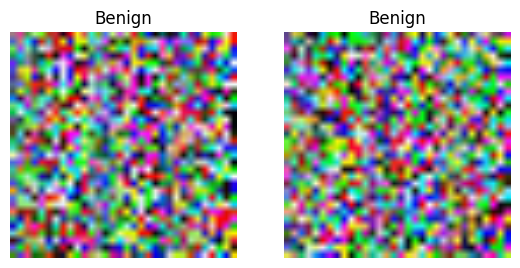

In [120]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_Xception = []
all_labels_Xception = []

for image_batch, label_batch in val_ds.as_numpy_iterator():
    predictions = model_Xception.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_Xception.append(predictions)
    all_labels_Xception.append(label_batch)

all_predictions_Xception = np.concatenate(all_predictions_Xception)
all_labels_Xception = np.concatenate(all_labels_Xception)
print('Predictions:\n', all_predictions_Xception)
print('Labels:\n', all_labels_Xception)

report_Xception = classification_report(all_labels_Xception, all_predictions_Xception, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_Xception[i]])
    plt.axis("off")

val_ds (Xception)
                  
              precision    recall  f1-score   support

      Benign       0.97      1.00      0.99       640
GPS Spoofing       1.00      0.96      0.98       486

    accuracy                           0.98      1126
   macro avg       0.99      0.98      0.98      1126
weighted avg       0.98      0.98      0.98      1126

                  
1) Accuracy: 0.9831261101243339
                  
2) Precision: 0.983612610742904
                  
3) Recall: 0.9831261101243339
                  
4) Average F1-score: 0.9830813065293325
                  
5) F1-score for each type of attack: [0.98537336 0.98006296]
                  
6) Average ROC AUC: 0.9804526748971194
                  
7) Average PR AUC: 0.9777792396699048
                  
8) Balanced Accuracy: 0.9804526748971194
                  
9) Hinge: 0.5852575488454707
                  
10) Matthews Correlation Coefficient: 0.9660232640518537
                  
11) Jaccard Score: 0.9609053

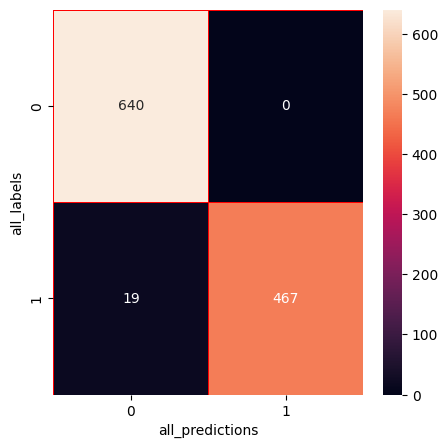

In [121]:
print("val_ds (Xception)")
print("                  ")
print(report_Xception)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_Xception , all_predictions_Xception, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_Xception , all_predictions_Xception, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_Xception , all_predictions_Xception, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_Xception , all_predictions_Xception, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_Xception , all_predictions_Xception, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_Xception , all_predictions_Xception, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_Xception ,all_predictions_Xception)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions")
plt.ylabel("all_labels")
plt.show()

In [122]:
saved_info = {
    'class_names': class_names,
    'all_labels_Xception': all_labels_Xception,
    'all_predictions_Xception': all_predictions_Xception,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_Xception , all_predictions_Xception),
    'precision_score': precision_score(all_labels_Xception , all_predictions_Xception, average='weighted'),
    'recall_score': recall_score(all_labels_Xception , all_predictions_Xception, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_Xception , all_predictions_Xception, average='weighted'),
    'f1_score_each': f1_score(all_labels_Xception , all_predictions_Xception, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_Xception , all_predictions_Xception, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_Xception , all_predictions_Xception, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_Xception , all_predictions_Xception),
    'Hinge': hinge_loss(all_labels_Xception , all_predictions_Xception),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_Xception , all_predictions_Xception),
    'Jaccard Score': jaccard_score(all_labels_Xception , all_predictions_Xception),
    'Log Loss': log_loss(all_labels_Xception , all_predictions_Xception),
    'Zero-One Loss': zero_one_loss(all_labels_Xception , all_predictions_Xception),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('Xception_val_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [123]:
with open('Xception_val_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_Xception'])
print("  ")
print("predictions:", saved_info['all_predictions_Xception'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [0 0 0 ... 0 0 0]
  
predictions: [0 0 0 ... 0 0 0]
  
cm: [[640   0]
 [ 19 467]]
  
1) Accuracy: 0.9831261101243339
  
2) Precision: 0.983612610742904
  
3) Recall: 0.9831261101243339
  
4) Average F1-score: 0.9830813065293325
  
5) F1-score for each type of attack: [0.98537336 0.98006296]
  
6) Average ROC AUC: 0.9804526748971194
  
7) Average PR AUC: 0.9777792396699048
  
8) Balanced Accuracy: 1.0
  
9) Hinge: 0.5852575488454707
  
10) Matthews Correlation Coefficient: 0.9660232640518537
  
11) Jaccard Score: 0.9609053497942387
  
12) Log Loss: 0.6081966380046414
  
13) Zero-One Loss: 0.01687388987566607
  
14) Prediction Overhead: 0.4305555555555556
  
15) Specificity: 1.0


## TL (Xception)

In [124]:
base_model_Xception.trainable = True
print("Number of layers in the base model: ", len(base_model_Xception.layers))
fine_tune_at_Xception = int((130/151)*len(base_model_Xception.layers))
for layer in base_model_Xception.layers[:fine_tune_at_Xception]:
  layer.trainable = False
print("frozen layers in the base model from layer 1 to ", fine_tune_at_Xception )
print("unfrozen layers in the base model from %2d to %3d " % (fine_tune_at_Xception+1,len(base_model_Xception.layers)))

Number of layers in the base model:  132
frozen layers in the base model from layer 1 to  113
unfrozen layers in the base model from 114 to 132 


In [125]:
history= LossHistory()
savepath='./Xception+TL.h5'
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
saveBestModel = kcallbacks.ModelCheckpoint(filepath=savepath, verbose=1, save_best_only=True, mode='auto')
model_Xception.compile(loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              optimizer = tf.keras.optimizers.Adam(learning_rate=0.00005/10),
              metrics=['accuracy'])
model_Xception.summary()
len(model_Xception.trainable_variables)

Model: "model_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_6 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 sequential (Sequential)     (None, 224, 224, 3)       0         
                                                                 
 tf.math.truediv_1 (TFOpLam  (None, 224, 224, 3)       0         
 bda)                                                            
                                                                 
 tf.math.subtract_1 (TFOpLa  (None, 224, 224, 3)       0         
 mbda)                                                           
                                                                 
 xception (Functional)       (None, 7, 7, 2048)        20861480  
                                                                 
 global_average_pooling2d_2  (None, 2048)              0   

25

In [126]:
%%time
fine_tune_epochs =5
total_epochs =  initial_epochs + fine_tune_epochs
history_fine_Xception = model_Xception.fit(train_ds, epochs=total_epochs, initial_epoch=history_Xception.epoch[-1], 
                                           validation_data=val_ds, callbacks=[early_stop, saveBestModel, history])

# Inference (Detection)
start_time = time.time()
detection_results = model_Xception.predict(val_ds)
end_time = time.time()

detection_time = end_time - start_time

print(f"Detection time: {detection_time} seconds")

Epoch 5/10
213/213 [==============================] - ETA: 0s - loss: 0.0368 - accuracy: 0.9881
Epoch 5: val_loss improved from inf to 0.03792, saving model to ./Xception+TL.h5


/usr/local/lib/python3.9/site-packages/keras/src/engine/training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


213/213 [==============================] - 21s 76ms/step - loss: 0.0368 - accuracy: 0.9881 - val_loss: 0.0379 - val_accuracy: 0.9840
Epoch 6/10
213/213 [==============================] - ETA: 0s - loss: 0.0229 - accuracy: 0.9925
Epoch 6: val_loss improved from 0.03792 to 0.03179, saving model to ./Xception+TL.h5
213/213 [==============================] - 15s 73ms/step - loss: 0.0229 - accuracy: 0.9925 - val_loss: 0.0318 - val_accuracy: 0.9867
Epoch 7/10
213/213 [==============================] - ETA: 0s - loss: 0.0182 - accuracy: 0.9944
Epoch 7: val_loss did not improve from 0.03179
213/213 [==============================] - 14s 68ms/step - loss: 0.0182 - accuracy: 0.9944 - val_loss: 0.0366 - val_accuracy: 0.9858
Epoch 8/10
213/213 [==============================] - ETA: 0s - loss: 0.0157 - accuracy: 0.9954
Epoch 8: val_loss did not improve from 0.03179
213/213 [==============================] - 15s 70ms/step - loss: 0.0157 - accuracy: 0.9954 - val_loss: 0.0421 - val_accuracy: 0.9867
E

## Xception Graph

In [127]:
acc_Xception += history_fine_Xception.history['accuracy']
val_acc_Xception += history_fine_Xception.history['val_accuracy']
loss_Xception += history_fine_Xception.history['loss']
val_loss_Xception += history_fine_Xception.history['val_loss']

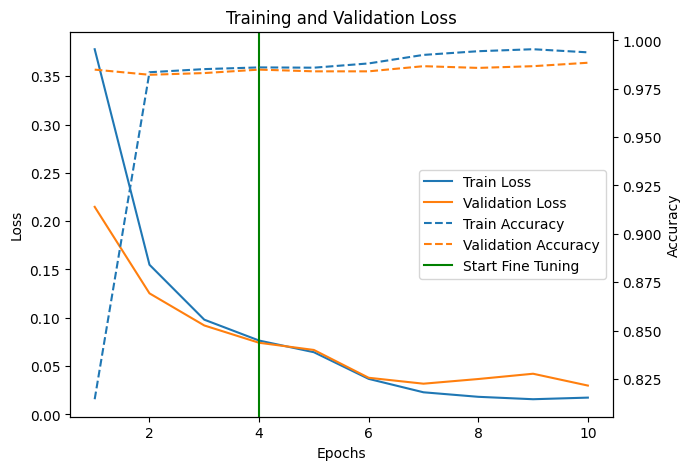

In [128]:
actual_epochs = range(1, total_epochs + 1)  
actual_train_loss = loss_Xception[:total_epochs]  
actual_val_loss = val_loss_Xception[:total_epochs]  
actual_train_accuracy = acc_Xception[:total_epochs]  
actual_val_accuracy = val_acc_Xception[:total_epochs]

fig, ax1 = plt.subplots(figsize=(7, 5))
ax1.plot(actual_epochs, actual_train_loss, '-', label='Train Loss')
ax1.plot(actual_epochs, actual_val_loss, '-', label='Validation Loss')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.set_title('Training and Validation Loss')
ax2 = ax1.twinx()
ax2.plot(actual_epochs, actual_train_accuracy, '--', label='Train Accuracy')
ax2.plot(actual_epochs, actual_val_accuracy, '--', label='Validation Accuracy')
ax2.set_ylabel('Accuracy')

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
custom_legend_elements = handles1 + handles2 + [plt.Line2D([0], [0], color='green', label='Start Fine Tuning')]
custom_legend_labels = labels1 + labels2 + ['Start Fine Tuning']
ax1.legend(custom_legend_elements, custom_legend_labels, loc='center right')
ax1.axvline(x=initial_epochs - 1, color='green')
plot_data = {'fig': fig, 'ax1': ax1, 'ax2': ax2}

learning_curve_data = {
    'train_loss': actual_train_loss,
    'val_loss': actual_val_loss,
    'train_acc': actual_train_accuracy,
    'val_acc': actual_val_accuracy
}
with open('Xception+Start Fine Tuning.pkl', 'wb') as file:
    pickle.dump(plot_data, file)
plt.savefig('Xception+Start Fine Tuning.pdf', format='pdf', dpi=300)
plt.savefig('Xception+Start Fine Tuning.svg', format='svg')
plt.savefig('Xception+Start Fine Tuning.png', format='png', dpi=300)
plt.show()

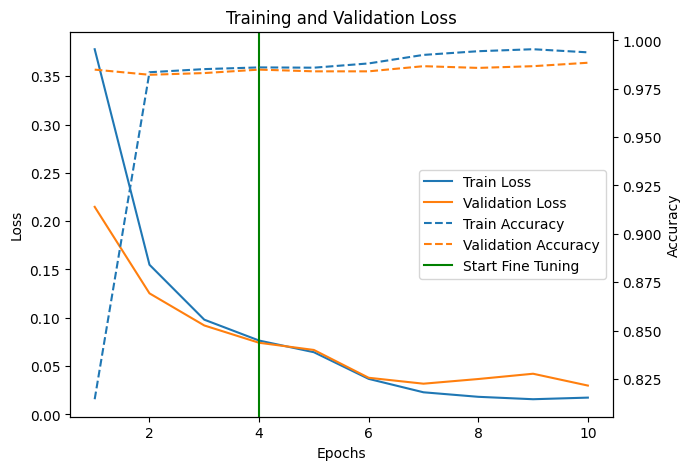

Training Loss: [0.3779272437095642, 0.1548851877450943, 0.09804315865039825, 0.07644727826118469, 0.06437220424413681, 0.036777615547180176, 0.022899489849805832, 0.0182188767939806, 0.015724768862128258, 0.017385432496666908]
Validation Loss: [0.21479633450508118, 0.12528689205646515, 0.09205280244350433, 0.07414992898702621, 0.06670761108398438, 0.03792159631848335, 0.03179258480668068, 0.036633819341659546, 0.04209946095943451, 0.029856687411665916]
Training Accuracy: [0.8145102262496948, 0.9835512042045593, 0.9851666688919067, 0.9860478639602661, 0.9859009981155396, 0.988103985786438, 0.9925099015235901, 0.9944191575050354, 0.9954472184181213, 0.9938316941261292]
Validation Accuracy: [0.9849023222923279, 0.9822379946708679, 0.9831261038780212, 0.9849023222923279, 0.9840142130851746, 0.9840142130851746, 0.9866784811019897, 0.9857904314994812, 0.9866784811019897, 0.9884546995162964]


In [129]:
with open('Xception+Start Fine Tuning.pkl', 'rb') as file:
    learning_curve = pickle.load(file)
fig = learning_curve['fig']
ax1 = learning_curve['ax1']
ax2 = learning_curve['ax2']
plt.show()

train_loss = learning_curve_data['train_loss']
val_loss = learning_curve_data['val_loss']
train_acc = learning_curve_data['train_acc']
val_acc = learning_curve_data['val_acc']
print("Training Loss:", learning_curve_data['train_loss'])
print("Validation Loss:", learning_curve_data['val_loss'])
print("Training Accuracy:", learning_curve_data['train_acc'])
print("Validation Accuracy:", learning_curve_data['val_acc'])

## Test_ds (Xception) + TL

Predictions:
 [1 1 1 1 1 0 1 1 0 0 1 1 0 1 1 0 1 0 0 0 0 0 0 1 1 1 0 1 0 0 1 1 0 0 1 1 0
 0 0 1 0 1 0 1 1 0 0 1 1 0 0 1 1 0 0 0 0 1 1 1 1 0 0 0 0 1 0 0 0 1 1 0 1 0
 0 0 1 0 0 1 0 0 1 1 1 0 0 1 0 1 0 1 1 0 1 0 0 0 1 0 0 1 0 1 1 1 0 0 0 1 0
 1 0 0 0 0 0 0 0 1 0 1 1 1 1 1 1 0 1 0 1 0 0 1 0 0 0 0 1 0 1 0 1 1 1 0 0 1
 0 0 1 1 0 0 0 1 0 0 0 0 0 0 0 1 0 1 1 1 0 1 0 1 1 1 1 0 0 1 0 0 1 0 1 0 0
 0 1 0 0 0 0 1 1 1 0 1 1 0 1 1 1 1 0 0 1 1 1 0 1 0 0 1 1 0 0 1 0 0 1 0 1 1
 0 0 1 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 1 0 1 1 1 0 0 0 0 1 0 0 1 0 0 0
 0 0 1 1 1 0 0 0 1 0 0 0 1 1 1 0 0 0 0 1 0 0 0 1 0 0 1 0 0 1 0 0 1 1 1 0 0
 0 0 0 0 1 0 1 1 0 1 0 0 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 0 0 1 1 0 0 1 0 1 0
 0 0 1 1 1 1 1 0 0 0 0 0 0 0 1 0 1 0 0 0 1 0 0 0 0 1 0 0 0 1 0 1 0 0 1 1 0
 1 1 0 1 1 0 1 0 1 0 0 1 0 0 1 1 0 0 1 0 1 0 1 0 1 0 0 1 1 0 1 0 1 0 1 0 1
 1 0 1 0 1 1 0 0 0 1 0 1 1 1 0 0 0 1 0 1 0 0 0 1 1 0 0 0 1 0 0 1 0 1 0 0 0
 0 1 1 1 1 0 0 1 0 0 0 1 0 0 0 1 1 0 0 0 1 0 1 1 1 0 0 1 1 0 0 0 1 0 0 1 1
 0 0 0 0 1 

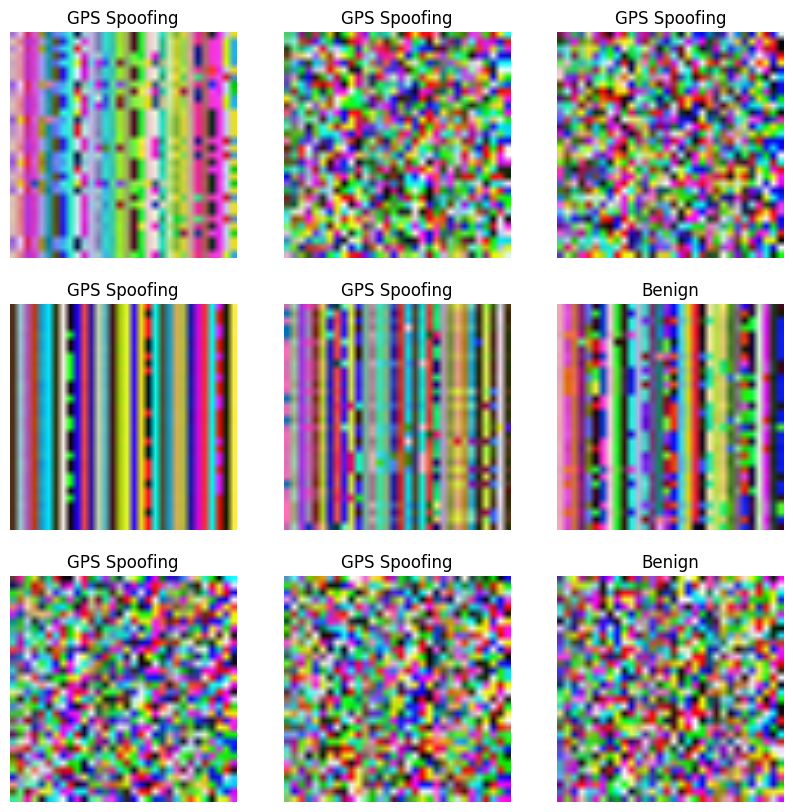

In [130]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_Xception = []
all_labels_Xception = []

for image_batch, label_batch in test_ds.as_numpy_iterator():
    predictions = model_Xception.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_Xception.append(predictions)
    all_labels_Xception.append(label_batch)
    
all_predictions_Xception = np.concatenate(all_predictions_Xception)
all_labels_Xception = np.concatenate(all_labels_Xception)
print('Predictions:\n', all_predictions_Xception)
print('Labels:\n', all_labels_Xception)
report_Xception = classification_report(all_labels_Xception, all_predictions_Xception, target_names=class_names_s)

plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_Xception[i]])
    plt.axis("off")

Test_ds+TL (Xception)
                  
              precision    recall  f1-score   support

      Benign       0.99      1.00      0.99       321
GPS Spoofing       1.00      0.98      0.99       255

    accuracy                           0.99       576
   macro avg       0.99      0.99      0.99       576
weighted avg       0.99      0.99      0.99       576

                  
1) Accuracy: 0.9930555555555556
                  
2) Precision: 0.9931410256410255
                  
3) Recall: 0.9930555555555556
                  
4) Average F1-score: 0.9930496069865432
                  
5) F1-score for each type of attack: [0.99380805 0.99209486]
                  
6) Average ROC AUC: 0.9921568627450981
                  
7) Average PR AUC: 0.9912581699346404
                  
8) Balanced Accuracy: 0.9921568627450981
                  
9) Hinge: 0.5642361111111112
                  
10) Matthews Correlation Coefficient: 0.9860015694828405
                  
11) Jaccard Score: 0.98

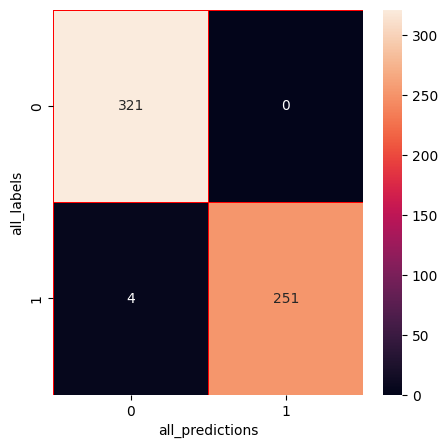

In [131]:
print("Test_ds+TL (Xception)")
print("                  ")
print(report_Xception)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_Xception , all_predictions_Xception, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_Xception , all_predictions_Xception, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_Xception , all_predictions_Xception, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_Xception , all_predictions_Xception, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_Xception , all_predictions_Xception, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_Xception , all_predictions_Xception, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_Xception ,all_predictions_Xception)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions")
plt.ylabel("all_labels")
plt.show()

In [132]:
loss_test_Xception, accuracy_test_Xception = model_Xception.evaluate(test_ds)
print("Test Loss Xception: {:.4f}".format(loss_test_Xception))
print("Test Accuracy Xception: {:.4f}".format(accuracy_test_Xception))

18/18 [==============================] - 2s 59ms/step - loss: 0.0082 - accuracy: 0.9931
Test Loss Xception: 0.0082
Test Accuracy Xception: 0.9931


In [133]:
saved_info = {
    'class_names': class_names,
    'all_labels_Xception': all_labels_Xception,
    'all_predictions_Xception': all_predictions_Xception,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_Xception , all_predictions_Xception),
    'precision_score': precision_score(all_labels_Xception , all_predictions_Xception, average='weighted'),
    'recall_score': recall_score(all_labels_Xception , all_predictions_Xception, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_Xception , all_predictions_Xception, average='weighted'),
    'f1_score_each': f1_score(all_labels_Xception , all_predictions_Xception, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_Xception , all_predictions_Xception, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_Xception , all_predictions_Xception, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_Xception , all_predictions_Xception),
    'Hinge': hinge_loss(all_labels_Xception , all_predictions_Xception),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_Xception , all_predictions_Xception),
    'Jaccard Score': jaccard_score(all_labels_Xception , all_predictions_Xception),
    'Log Loss': log_loss(all_labels_Xception , all_predictions_Xception),
    'Zero-One Loss': zero_one_loss(all_labels_Xception , all_predictions_Xception),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}
with open('Xception_Test (TL)_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [134]:
#=========

In [135]:
with open('Xception_Test (TL)_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)
    
print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_Xception'])
print("  ")
print("predictions:", saved_info['all_predictions_Xception'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [1 1 1 1 1 0 1 1 0 0 1 1 0 1 1 0 1 0 0 0 0 0 0 1 1 1 0 1 0 0 1 1 0 0 1 1 0
 0 0 1 0 1 1 1 1 0 0 1 1 0 0 1 1 0 0 0 0 1 1 1 1 0 0 0 0 1 0 0 0 1 1 0 1 0
 0 0 1 0 0 1 0 0 1 1 1 0 0 1 0 1 0 1 1 0 1 0 0 0 1 0 1 1 0 1 1 1 0 0 0 1 0
 1 0 0 0 0 0 0 0 1 0 1 1 1 1 1 1 0 1 0 1 0 0 1 0 0 0 0 1 0 1 0 1 1 1 0 0 1
 0 0 1 1 0 0 0 1 0 0 0 0 0 0 0 1 0 1 1 1 0 1 0 1 1 1 1 0 0 1 0 0 1 0 1 0 0
 0 1 0 0 0 0 1 1 1 0 1 1 0 1 1 1 1 0 0 1 1 1 0 1 0 0 1 1 0 0 1 0 0 1 0 1 1
 0 0 1 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 1 0 1 1 1 0 0 0 0 1 0 0 1 0 0 0
 0 0 1 1 1 0 0 0 1 0 0 0 1 1 1 0 0 0 0 1 0 0 0 1 0 0 1 0 0 1 0 0 1 1 1 0 0
 0 0 0 0 1 0 1 1 0 1 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 0 0 1 1 0 0 1 0 1 0
 0 0 1 1 1 1 1 0 0 0 0 0 0 1 1 0 1 0 0 0 1 0 0 0 0 1 0 0 0 1 0 1 0 0 1 1 0
 1 1 0 1 1 0 1 0 1 0 0 1 0 0 1 1 0 0 1 0 1 0 1 0 1 0 0 1 1 0 1 0 1 0 1 0 1
 1 0 1 0 1 1 0 0 0 1 0 1 1 1 0 0 0 1 0 1 0 0 0 1 1 0 0 0 1 0 0 1 0 1 0 0 0
 0 1 1 1 1 0 0 1 0 0 0 1 0 0 0 1 1 0 0 0 1 0 1 1 1 0 0 1 1 0 0 0 1

## Val_ds (Xception) + TL

Predictions:
 [1 0 1 ... 0 1 0]
Labels:
 [1 0 1 ... 0 1 0]


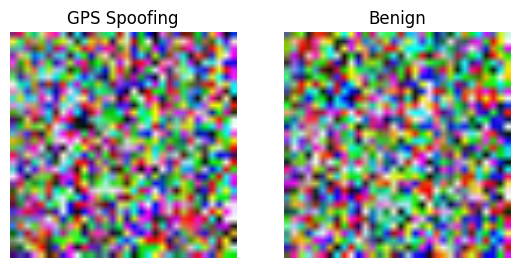

In [136]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_Xception = []
all_labels_Xception = []

for image_batch, label_batch in val_ds.as_numpy_iterator():
    predictions = model_Xception.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_Xception.append(predictions)
    all_labels_Xception.append(label_batch)
    
all_predictions_Xception = np.concatenate(all_predictions_Xception)
all_labels_Xception = np.concatenate(all_labels_Xception)
print('Predictions:\n', all_predictions_Xception)
print('Labels:\n', all_labels_Xception)
report_Xception = classification_report(all_labels_Xception, all_predictions_Xception, target_names=class_names_s)

plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_Xception[i]])
    plt.axis("off")

val_ds+TL(Xception)
                  
              precision    recall  f1-score   support

      Benign       0.99      1.00      0.99       642
GPS Spoofing       1.00      0.99      0.99       484

    accuracy                           0.99      1126
   macro avg       0.99      0.99      0.99      1126
weighted avg       0.99      0.99      0.99      1126

                  
1) Accuracy: 0.9937833037300178
                  
2) Precision: 0.993850355923993
                  
3) Recall: 0.9937833037300178
                  
4) Average F1-score: 0.9937775162166946
                  
5) F1-score for each type of attack: [0.99457785 0.99271592]
                  
6) Average ROC AUC: 0.9927685950413223
                  
7) Average PR AUC: 0.9917538863526268
                  
8) Balanced Accuracy: 0.9927685950413223
                  
9) Hinge: 0.5763765541740675
                  
10) Matthews Correlation Coefficient: 0.9873739712311663
                  
11) Jaccard Score: 0.98553

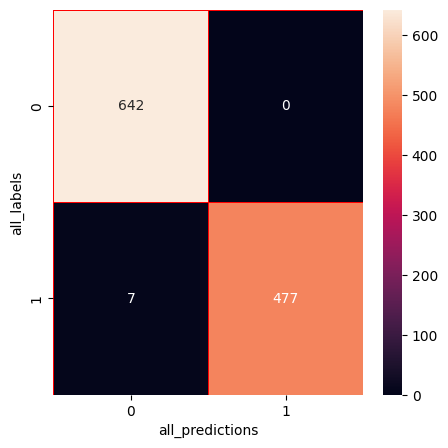

In [137]:
print("val_ds+TL(Xception)")
print("                  ")
print(report_Xception)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_Xception , all_predictions_Xception, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_Xception , all_predictions_Xception, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_Xception , all_predictions_Xception, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_Xception , all_predictions_Xception, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_Xception , all_predictions_Xception, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_Xception , all_predictions_Xception, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_Xception , all_predictions_Xception)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_Xception ,all_predictions_Xception)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions")
plt.ylabel("all_labels")
plt.show()

In [138]:
loss_Validation_Xception, accuracy_Validation_Xception = model_Xception.evaluate(val_ds)
print("Validation loss_Xception: {:.4f}".format(loss_Validation_Xception))
print("Validation accuracy_Xception: {:.4f}".format(accuracy_Validation_Xception))

36/36 [==============================] - 4s 55ms/step - loss: 0.0161 - accuracy: 0.9902
Validation loss_Xception: 0.0161
Validation accuracy_Xception: 0.9902


In [139]:
saved_info = {
    'class_names': class_names,
    'all_labels_Xception': all_labels_Xception,
    'all_predictions_Xception': all_predictions_Xception,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_Xception , all_predictions_Xception),
    'precision_score': precision_score(all_labels_Xception , all_predictions_Xception, average='weighted'),
    'recall_score': recall_score(all_labels_Xception , all_predictions_Xception, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_Xception , all_predictions_Xception, average='weighted'),
    'f1_score_each': f1_score(all_labels_Xception , all_predictions_Xception, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_Xception , all_predictions_Xception, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_Xception , all_predictions_Xception, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_Xception , all_predictions_Xception),
    'Hinge': hinge_loss(all_labels_Xception , all_predictions_Xception),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_Xception , all_predictions_Xception),
    'Jaccard Score': jaccard_score(all_labels_Xception , all_predictions_Xception),
    'Log Loss': log_loss(all_labels_Xception , all_predictions_Xception),
    'Zero-One Loss': zero_one_loss(all_labels_Xception , all_predictions_Xception),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('Xception_Val(TL)_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [140]:
#=========

In [141]:
with open('Xception_Val(TL)_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)
    
print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_Xception'])
print("  ")
print("predictions:", saved_info['all_predictions_Xception'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [1 0 1 ... 0 1 0]
  
predictions: [1 0 1 ... 0 1 0]
  
cm: [[642   0]
 [  7 477]]
  
1) Accuracy: 0.9937833037300178
  
2) Precision: 0.993850355923993
  
3) Recall: 0.9937833037300178
  
4) Average F1-score: 0.9937775162166946
  
5) F1-score for each type of attack: [0.99457785 0.99271592]
  
6) Average ROC AUC: 0.9927685950413223
  
7) Average PR AUC: 0.9917538863526268
  
8) Balanced Accuracy: 1.0
  
9) Hinge: 0.5763765541740675
  
10) Matthews Correlation Coefficient: 0.9873739712311663
  
11) Jaccard Score: 0.9855371900826446
  
12) Log Loss: 0.22407244558065745
  
13) Zero-One Loss: 0.006216696269982225
  
14) Prediction Overhead: 0.4305555555555556
  
15) Specificity: 1.0


## Load the saved model and learning curve

In [142]:
new_model = tf.keras.models.load_model('./Xception+TL.h5')

In [143]:
for layer in new_model.layers:
    print(layer.name)
    weights = layer.get_weights()
    for weight in weights:
        print(weight)

input_6
sequential
tf.math.truediv_1
tf.math.subtract_1
xception
[[[[ 4.01871502e-01  6.77069500e-02 -9.92160812e-02 -2.40881741e-01
     4.94409263e-01 -1.35092044e+00 -7.53455386e-02 -1.15802072e-01
     2.54089713e-01  4.12381589e-01 -2.02945337e-01 -5.65736771e-01
     1.53094187e-01 -5.43646663e-02  9.78396833e-02 -2.72699267e-01
    -9.39905122e-02  3.93782228e-01  3.33525687e-01  2.95914084e-01
    -3.14331800e-02 -1.99261308e-01  1.59772888e-01 -3.25841278e-01
    -1.50597319e-01 -7.27500841e-02  1.80662051e-02  3.05232316e-01
     8.96351188e-02  2.89342284e-01 -2.50950217e-01 -7.65512884e-01]
   [ 4.84812856e-02  4.23621461e-02  4.00314759e-03 -3.78118306e-02
    -5.52299500e-01  7.35755444e-01 -3.38940531e-01 -1.09324297e-02
    -8.63540769e-02 -7.23446161e-02 -5.50143421e-01 -5.00105917e-01
     2.29335129e-01  2.17402652e-01 -1.51911721e-01 -3.03186446e-01
     1.59955341e-02  7.01382399e-01 -6.02655232e-01 -3.59203607e-01
     1.69193089e-01  3.54705423e-01  2.15480939e-0

In [144]:
print(new_model.get_config())

{'name': 'model_2', 'trainable': True, 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_input_shape': (None, 224, 224, 3), 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'input_6'}, 'registered_name': None, 'name': 'input_6', 'inbound_nodes': []}, {'module': 'keras', 'class_name': 'Sequential', 'config': {'name': 'sequential', 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_input_shape': (None, 224, 224, 3), 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'random_flip_input'}, 'registered_name': None}, {'module': 'keras.layers', 'class_name': 'RandomFlip', 'config': {'name': 'random_flip', 'trainable': True, 'dtype': 'float32', 'mode': 'horizontal_and_vertical', 'seed': None}, 'registered_name': None, 'build_config': {'input_shape': (None, 224, 224, 3)}}, {'module': 'keras.layers', 'class_name': 'RandomRotation', 'config': {'name': 'random_rotation', 'trainable': True, 'dtype': 'float32'

# VGG16

# InceptionResNetV2 model

In [14]:
IMG_SHAPE = (img_height, img_width,3)
base_model_InceptionResNetV2 = tf.keras.applications.InceptionResNetV2(input_shape=IMG_SHAPE,
                                               include_top=False,   
                                               weights='imagenet')

In [ ]:
base_model_InceptionResNetV2.trainable = False
base_model_InceptionResNetV2.summary()

Model: "inception_resnet_v2"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 224, 224, 3)]        0         []                            
                                                                                                  
 conv2d (Conv2D)             (None, 111, 111, 32)         864       ['input_1[0][0]']             
                                                                                                  
 batch_normalization (Batch  (None, 111, 111, 32)         96        ['conv2d[0][0]']              
 Normalization)                                                                                   
                                                                                                  
 activation (Activation)     (None, 111, 111, 32)         0         ['batch_norm

 atchNormalization)                                                                               
                                                                                                  
 activation_436 (Activation  (None, 25, 25, 32)           0         ['batch_normalization_436[0][0
 )                                                                  ]']                           
                                                                                                  
 activation_438 (Activation  (None, 25, 25, 32)           0         ['batch_normalization_438[0][0
 )                                                                  ]']                           
                                                                                                  
 activation_441 (Activation  (None, 25, 25, 64)           0         ['batch_normalization_441[0][0
 )                                                                  ]']                           
          

 conv2d_451 (Conv2D)         (None, 25, 25, 32)           10240     ['block35_5_ac[0][0]']        
                                                                                                  
 batch_normalization_451 (B  (None, 25, 25, 32)           96        ['conv2d_451[0][0]']          
 atchNormalization)                                                                               
                                                                                                  
 activation_451 (Activation  (None, 25, 25, 32)           0         ['batch_normalization_451[0][0
 )                                                                  ]']                           
                                                                                                  
 conv2d_449 (Conv2D)         (None, 25, 25, 32)           10240     ['block35_5_ac[0][0]']        
                                                                                                  
 conv2d_45

                                                                                                  
 conv2d_454 (Conv2D)         (None, 25, 25, 32)           10240     ['block35_6_ac[0][0]']        
                                                                                                  
 conv2d_456 (Conv2D)         (None, 25, 25, 32)           9216      ['activation_455[0][0]']      
                                                                                                  
 conv2d_459 (Conv2D)         (None, 25, 25, 64)           27648     ['activation_458[0][0]']      
                                                                                                  
 batch_normalization_454 (B  (None, 25, 25, 32)           96        ['conv2d_454[0][0]']          
 atchNormalization)                                                                               
                                                                                                  
 batch_nor

 )                                                                  ]']                           
                                                                                                  
 block35_8_mixed (Concatena  (None, 25, 25, 128)          0         ['activation_460[0][0]',      
 te)                                                                 'activation_462[0][0]',      
                                                                     'activation_465[0][0]']      
                                                                                                  
 block35_8_conv (Conv2D)     (None, 25, 25, 320)          41280     ['block35_8_mixed[0][0]']     
                                                                                                  
 custom_scale_layer_87 (Cus  (None, 25, 25, 320)          0         ['block35_7_ac[0][0]',        
 tomScaleLayer)                                                      'block35_8_conv[0][0]']      
          

                                                                                                  
 conv2d_476 (Conv2D)         (None, 25, 25, 48)           13824     ['activation_475[0][0]']      
                                                                                                  
 batch_normalization_473 (B  (None, 25, 25, 32)           96        ['conv2d_473[0][0]']          
 atchNormalization)                                                                               
                                                                                                  
 batch_normalization_476 (B  (None, 25, 25, 48)           144       ['conv2d_476[0][0]']          
 atchNormalization)                                                                               
                                                                                                  
 activation_473 (Activation  (None, 25, 25, 32)           0         ['batch_normalization_473[0][0
 )        

... (13 outputs left out)

                                                                                                  
 batch_normalization_581 (B  (None, 5, 5, 192)            576       ['conv2d_581[0][0]']          
 atchNormalization)                                                                               
                                                                                                  
 batch_normalization_584 (B  (None, 5, 5, 256)            768       ['conv2d_584[0][0]']          
 atchNormalization)                                                                               
                                                                                                  
 activation_581 (Activation  (None, 5, 5, 192)            0         ['batch_normalization_581[0][0
 )                                                                  ]']                           
                                                                                                  
 activatio

 conv2d_589 (Conv2D)         (None, 5, 5, 192)            399360    ['block8_5_ac[0][0]']         
                                                                                                  
 conv2d_592 (Conv2D)         (None, 5, 5, 256)            172032    ['activation_591[0][0]']      
                                                                                                  
 batch_normalization_589 (B  (None, 5, 5, 192)            576       ['conv2d_589[0][0]']          
 atchNormalization)                                                                               
                                                                                                  
 batch_normalization_592 (B  (None, 5, 5, 256)            768       ['conv2d_592[0][0]']          
 atchNormalization)                                                                               
                                                                                                  
 activatio

 activation_599 (Activation  (None, 5, 5, 224)            0         ['batch_normalization_599[0][0
 )                                                                  ]']                           
                                                                                                  
 conv2d_597 (Conv2D)         (None, 5, 5, 192)            399360    ['block8_7_ac[0][0]']         
                                                                                                  
 conv2d_600 (Conv2D)         (None, 5, 5, 256)            172032    ['activation_599[0][0]']      
                                                                                                  
 batch_normalization_597 (B  (None, 5, 5, 192)            576       ['conv2d_597[0][0]']          
 atchNormalization)                                                                               
                                                                                                  
 batch_nor

 batch_normalization_607 (B  (None, 5, 5, 224)            672       ['conv2d_607[0][0]']          
 atchNormalization)                                                                               
                                                                                                  
 activation_607 (Activation  (None, 5, 5, 224)            0         ['batch_normalization_607[0][0
 )                                                                  ]']                           
                                                                                                  
 conv2d_605 (Conv2D)         (None, 5, 5, 192)            399360    ['block8_9_ac[0][0]']         
                                                                                                  
 conv2d_608 (Conv2D)         (None, 5, 5, 256)            172032    ['activation_607[0][0]']      
                                                                                                  
 batch_nor

In [ ]:
image_batch, label_batch = next(iter(train_ds)) 
feature_batch_InceptionResNetV2 = base_model_InceptionResNetV2(image_batch)
print(feature_batch_InceptionResNetV2.shape)
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
feature_batch_average_InceptionResNetV2 = global_average_layer(feature_batch_InceptionResNetV2)
print(feature_batch_average_InceptionResNetV2.shape)
prediction_layer_InceptionResNetV2 = tf.keras.layers.Dense(1)
prediction_batch_InceptionResNetV2 = prediction_layer_InceptionResNetV2(feature_batch_average_InceptionResNetV2)
print(prediction_batch_InceptionResNetV2.shape)

In [ ]:
inputs_InceptionResNetV2 = tf.keras.Input(shape=(img_height, img_width,3))
x_InceptionResNetV2 = data_augmentation(inputs_InceptionResNetV2)
x_InceptionResNetV2 = tf.keras.applications.inception_resnet_v2.preprocess_input (x_InceptionResNetV2) 
x_InceptionResNetV2 = base_model_InceptionResNetV2(x_InceptionResNetV2, training=False)  
x_InceptionResNetV2 = global_average_layer(x_InceptionResNetV2)  
x_InceptionResNetV2 = tf.keras.layers.Dropout(0.2)(x_InceptionResNetV2) 
outputs_InceptionResNetV2 = prediction_layer_InceptionResNetV2(x_InceptionResNetV2)
model_InceptionResNetV2 = tf.keras.Model(inputs_InceptionResNetV2, outputs_InceptionResNetV2)

In [ ]:
class LossHistory(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs={}):
        self.losses = {'batch':[], 'epoch':[]}
        self.accuracy = {'batch':[], 'epoch':[]}
        self.val_loss = {'batch':[], 'epoch':[]}
        self.val_acc = {'batch':[], 'epoch':[]}
        self.history = {}
    def on_batch_end(self, batch, logs={}):
        self.losses['batch'].append(logs.get('loss'))
        self.accuracy['batch'].append(logs.get('accuracy'))
        self.val_loss['batch'].append(logs.get('val_loss'))
        self.val_acc['batch'].append(logs.get('val_accuracy'))
    def on_epoch_end(self, batch, logs={}):
        self.losses['epoch'].append(logs.get('loss'))
        self.accuracy['epoch'].append(logs.get('accuracy'))
        self.val_loss['epoch'].append(logs.get('val_loss'))
        self.val_acc['epoch'].append(logs.get('val_accuracy'))
        self.history = {'loss': self.losses, 'accuracy': self.accuracy, 'val_loss': self.val_loss, 'val_accuracy': self.val_acc}

In [ ]:
history= LossHistory()
base_learning_rate = 0.00007
savepath='./InceptionResNetV2.h5'
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
saveBestModel = kcallbacks.ModelCheckpoint(filepath=savepath, verbose=1,save_best_only=True, mode='auto')
model_InceptionResNetV2.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
              loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [ ]:
model_InceptionResNetV2.summary()

In [ ]:
initial_epochs = 5
loss0, accuracy0 = model_InceptionResNetV2.evaluate(val_ds)

In [ ]:
print("initial loss: {:.4f}".format(loss0))
print("initial accuracy: {:.4f}".format(accuracy0))

In [ ]:
%%time
history_InceptionResNetV2 = model_InceptionResNetV2.fit(train_ds, epochs=initial_epochs, validation_data=val_ds,
                    callbacks=[early_stop, saveBestModel, history])
# Inference (Detection)
start_time = time.time()
detection_results = model_InceptionResNetV2.predict(val_ds)
end_time = time.time()

detection_time = end_time - start_time

print(f"Detection time: {detection_time} seconds")

In [24]:
acc_InceptionResNetV2 = history_InceptionResNetV2.history['accuracy']
val_acc_InceptionResNetV2 = history_InceptionResNetV2.history['val_accuracy']
loss_InceptionResNetV2 = history_InceptionResNetV2.history['loss']
val_loss_InceptionResNetV2 = history_InceptionResNetV2.history['val_loss']

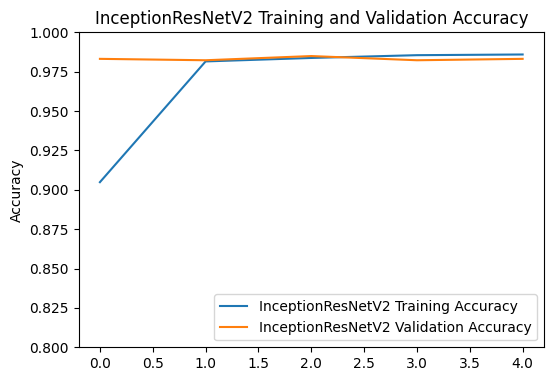

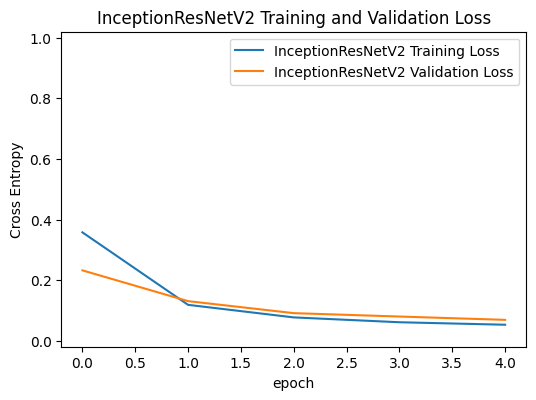

In [25]:
plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 1)
plt.plot(acc_InceptionResNetV2, label='InceptionResNetV2 Training Accuracy')
plt.plot(val_acc_InceptionResNetV2, label='InceptionResNetV2 Validation Accuracy')
plt.ylim([0.8, 1.01])
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),1])
plt.title('InceptionResNetV2 Training and Validation Accuracy')
plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 2)
plt.plot(loss_InceptionResNetV2, label='InceptionResNetV2 Training Loss')
plt.plot(val_loss_InceptionResNetV2, label='InceptionResNetV2 Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([-0.02, 1.02])
plt.title('InceptionResNetV2 Training and Validation Loss')
plt.xlabel('epoch')

plt.savefig('InceptionResNetV2+ORG.pdf', format='pdf', dpi=300)
plt.savefig('InceptionResNetV2+ORG.svg', format='svg')
plt.savefig('InceptionResNetV2+ORG.png', format='png', dpi=300)
plt.show()

## Test_ds (InceptionResNetV2)

Predictions:
 [0 1 0 0 0 1 1 0 1 0 0 0 0 1 0 1 1 0 0 0 0 0 0 1 1 1 1 0 1 1 0 0 1 0 0 1 1
 0 1 1 1 0 0 0 1 0 1 1 1 1 0 0 1 1 1 1 0 0 0 1 0 0 1 0 1 0 1 1 1 0 1 0 1 1
 0 0 1 0 0 0 0 0 0 0 0 1 0 0 1 0 1 0 1 0 1 0 0 0 0 1 1 1 0 0 0 0 1 0 1 1 0
 0 1 1 1 0 1 0 0 1 0 1 1 0 0 0 0 1 0 1 1 0 1 0 0 1 0 0 0 0 0 1 1 1 0 0 0 0
 0 1 0 0 0 1 0 0 0 0 0 0 1 0 0 0 1 0 0 1 1 0 1 1 1 1 0 0 0 0 1 0 1 1 1 1 1
 1 1 0 0 1 1 1 0 0 1 0 0 0 0 0 1 0 0 1 0 1 0 0 0 1 0 1 1 0 1 0 1 1 0 0 1 0
 0 0 0 0 0 1 0 1 0 1 0 0 1 1 1 1 0 1 1 1 0 1 0 1 0 0 1 0 0 1 0 1 0 1 1 1 0
 1 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 1 1 1 0 1 1 0 1 0 1 0 1 1 0
 1 0 1 0 0 0 0 1 0 1 1 0 0 0 1 0 0 1 0 0 1 0 0 1 1 1 1 0 1 1 0 0 1 1 0 1 1
 0 0 1 0 1 1 0 0 0 0 1 1 0 0 0 0 1 1 1 0 0 0 1 1 0 0 0 0 1 0 0 1 0 0 0 1 0
 0 1 1 0 0 0 0 0 1 0 0 1 1 1 1 0 0 1 1 0 0 0 1 0 1 0 0 0 0 0 1 1 1 0 1 1 0
 1 0 0 0 1 1 1 0 0 1 0 0 0 1 0 1 0 1 1 0 1 1 0 0 0 0 0 0 0 0 1 0 1 1 0 0 0
 0 1 1 1 0 0 1 1 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0 1 1 1 1 0 0 1 1 1 0 0 0
 1 0 0 1 1 

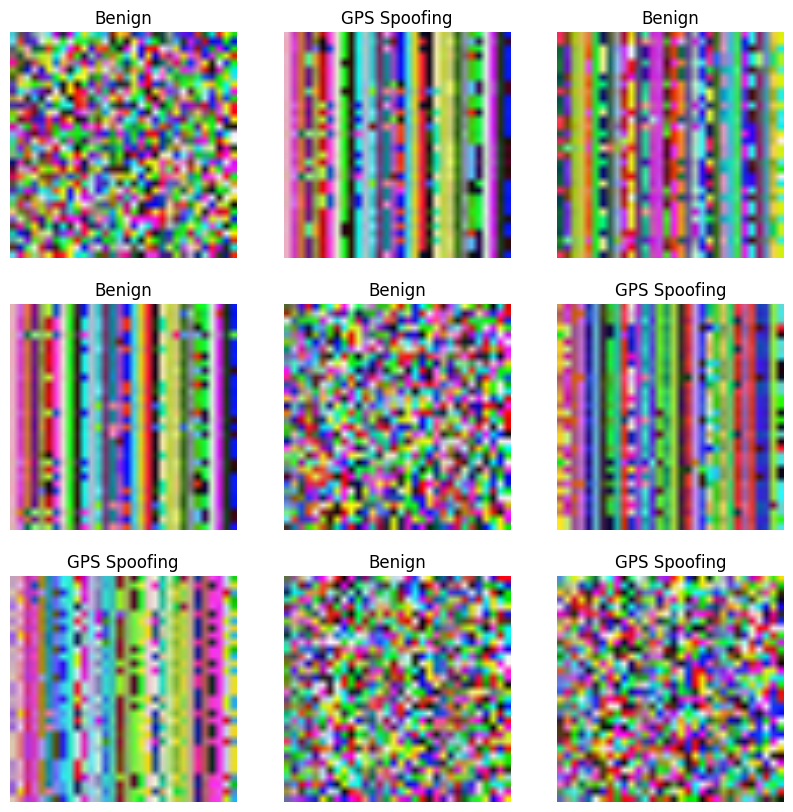

In [26]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_InceptionResNetV2 = []
all_labels_InceptionResNetV2 = []

for image_batch, label_batch in test_ds.as_numpy_iterator():
    predictions = model_InceptionResNetV2.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_InceptionResNetV2.append(predictions)
    all_labels_InceptionResNetV2.append(label_batch)

all_predictions_InceptionResNetV2 = np.concatenate(all_predictions_InceptionResNetV2)
all_labels_InceptionResNetV2 = np.concatenate(all_labels_InceptionResNetV2)
print('Predictions:\n', all_predictions_InceptionResNetV2)
print('Labels:\n', all_labels_InceptionResNetV2)
report_InceptionResNetV2 = classification_report(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, 
                                                 target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_InceptionResNetV2[i]])
    plt.axis("off")

In [27]:
cm=confusion_matrix(all_labels_InceptionResNetV2 ,all_predictions_InceptionResNetV2)
TP = np.sum((all_predictions_InceptionResNetV2 == 1) & (all_labels_InceptionResNetV2 == 1))
FP = np.sum((all_predictions_InceptionResNetV2 == 1) & (all_labels_InceptionResNetV2 == 0))
FN = np.sum((all_predictions_InceptionResNetV2 == 0) & (all_labels_InceptionResNetV2 == 1))
TN = cm[0, 0]
DA = (TP + TN) / len(all_labels_InceptionResNetV2)
DP = TP / (TP + FP)
DS = TP / (TP + FN)
DF = 2 * (DP * DS) / (DP + DS)
DE = 1 - DA
FR = FP / (FP + TN)
total_predictions = TP + FP + TN + FN
prediction_overhead = (TP + FP) / total_predictions
TN, FP, FN, TP = confusion_matrix(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2).ravel()
specificity = TN / (TN + FP)

test_ds (InceptionResNetV2)
                  
              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99       332
GPS Spoofing       1.00      0.97      0.98       244

    accuracy                           0.99       576
   macro avg       0.99      0.98      0.99       576
weighted avg       0.99      0.99      0.99       576

                  
1) Accuracy: 0.9861111111111112
                  
2) Precision: 0.9864379084967321
                  
3) Recall: 0.9861111111111112
                  
4) Average F1-score: 0.9860780423280422
                  
5) F1-score for each type of attack: [0.98809524 0.98333333]
                  
6) Average ROC AUC: 0.9836065573770492
                  
7) Average PR AUC: 0.9811020036429873
                  
8) Balanced Accuracy: 0.9836065573770492
                  
9) Hinge: 0.5902777777777778
                  
10) Matthews Correlation Coefficient: 0.9718308284433178
                  
11) Jaccard Score

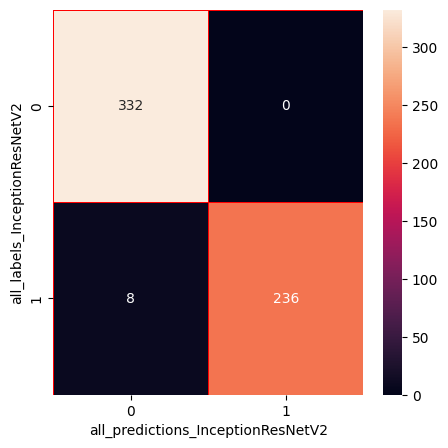

In [28]:
print("test_ds (InceptionResNetV2)")
print("                  ")
print(report_InceptionResNetV2)
print("                  ")
print("1) Accuracy: "+ str(accuracy_score(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, 
                                                  average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2,
                                                           average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_InceptionResNetV2 ,all_predictions_InceptionResNetV2)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_InceptionResNetV2")
plt.ylabel("all_labels_InceptionResNetV2")
plt.show()

In [29]:
loss_test_InceptionResNetV2, accuracy_test_InceptionResNetV2 = model_InceptionResNetV2.evaluate(test_ds) 
print("test loss_InceptionResNetV2: {:.4f}".format(loss_test_InceptionResNetV2))
print("test accuracy_InceptionResNetV2: {:.4f}".format(accuracy_test_InceptionResNetV2))

18/18 [==============================] - 2s 74ms/step - loss: 0.0542 - accuracy: 0.9913
test loss_InceptionResNetV2: 0.0542
test accuracy_InceptionResNetV2: 0.9913


In [30]:
saved_info = {
    'class_names': class_names,
    'all_labels_InceptionResNetV2': all_labels_InceptionResNetV2,
    'all_predictions_InceptionResNetV2': all_predictions_InceptionResNetV2,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'precision_score': precision_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average='weighted'),
    'recall_score': recall_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average='weighted'),
    'f1_score_each': f1_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'Hinge': hinge_loss(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'Jaccard Score': jaccard_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'Log Loss': log_loss(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'Zero-One Loss': zero_one_loss(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('InceptionResNetV2_test_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [31]:
with open('InceptionResNetV2_test_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_InceptionResNetV2'])
print("  ")
print("predictions:", saved_info['all_predictions_InceptionResNetV2'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [0 1 0 0 0 1 1 0 1 0 0 0 0 1 0 1 1 0 0 0 0 0 0 1 1 1 1 0 1 1 0 0 1 0 0 1 1
 0 1 1 1 1 0 0 1 0 1 1 1 1 0 0 1 1 1 1 0 0 0 1 0 0 1 0 1 0 1 1 1 0 1 0 1 1
 0 0 1 0 0 0 0 0 0 0 0 1 0 0 1 0 1 0 1 0 1 0 0 0 0 1 1 1 0 0 0 0 1 0 1 1 0
 0 1 1 1 0 1 0 0 1 0 1 1 0 0 0 1 1 0 1 1 0 1 0 0 1 0 0 0 0 0 1 1 1 0 0 0 0
 0 1 0 0 0 1 0 0 0 0 0 0 1 0 0 0 1 0 0 1 1 0 1 1 1 1 0 1 0 0 1 0 1 1 1 1 1
 1 1 1 0 1 1 1 0 0 1 0 0 0 0 0 1 0 0 1 0 1 0 0 0 1 0 1 1 0 1 0 1 1 0 0 1 0
 0 0 0 0 0 1 0 1 0 1 0 0 1 1 1 1 0 1 1 1 0 1 0 1 0 0 1 0 0 1 0 1 0 1 1 1 0
 1 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 1 1 1 0 1 1 0 1 0 1 0 1 1 0
 1 0 1 0 0 0 0 1 0 1 1 0 0 0 1 0 0 1 0 0 1 0 0 1 1 1 1 0 1 1 0 0 1 1 0 1 1
 0 0 1 0 1 1 0 0 0 0 1 1 0 0 0 0 1 1 1 0 0 0 1 1 0 0 0 0 1 0 0 1 0 0 0 1 0
 0 1 1 0 0 0 0 0 1 0 0 1 1 1 1 0 0 1 1 0 0 1 1 0 1 0 0 0 0 0 1 1 1 0 1 1 0
 1 0 0 0 1 1 1 0 0 1 0 0 0 1 0 1 0 1 1 0 1 1 0 0 0 0 0 0 0 0 1 0 1 1 0 0 1
 0 1 1 1 0 1 1 1 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0 1 1 1 1 1 0 1 1

## Val_ds InceptionResNetV2

Predictions:
 [0 1 0 ... 1 0 1]
Labels:
 [0 1 0 ... 1 0 1]


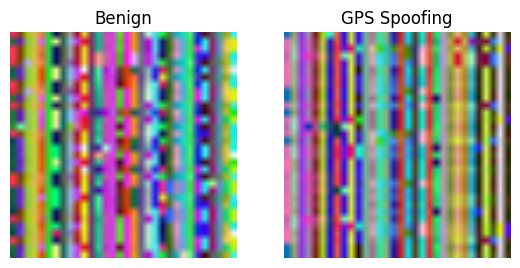

In [32]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_InceptionResNetV2 = []
all_labels_InceptionResNetV2 = []

for image_batch, label_batch in val_ds.as_numpy_iterator():
    predictions = model_InceptionResNetV2.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_InceptionResNetV2.append(predictions)
    all_labels_InceptionResNetV2.append(label_batch)

all_predictions_InceptionResNetV2 = np.concatenate(all_predictions_InceptionResNetV2)
all_labels_InceptionResNetV2 = np.concatenate(all_labels_InceptionResNetV2)
print('Predictions:\n', all_predictions_InceptionResNetV2)
print('Labels:\n', all_labels_InceptionResNetV2)

report_InceptionResNetV2 = classification_report(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, 
                                                 target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_InceptionResNetV2[i]])
    plt.axis("off")

val_ds (InceptionResNetV2)
                  
              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99       640
GPS Spoofing       1.00      0.97      0.98       486

    accuracy                           0.99      1126
   macro avg       0.99      0.98      0.99      1126
weighted avg       0.99      0.99      0.99      1126

                  
1) Accuracy: 0.9857904085257548
                  
2) Precision: 0.9861369839275659
                  
3) Recall: 0.9857904085257548
                  
4) Average F1-score: 0.985759213338108
                  
5) F1-score for each type of attack: [0.98765432 0.9832636 ]
                  
6) Average ROC AUC: 0.9835390946502058
                  
7) Average PR AUC: 0.9812877807746566
                  
8) Balanced Accuracy: 0.9835390946502058
                  
9) Hinge: 0.5825932504440497
                  
10) Matthews Correlation Coefficient: 0.9713346057825004
                  
11) Jaccard Score: 

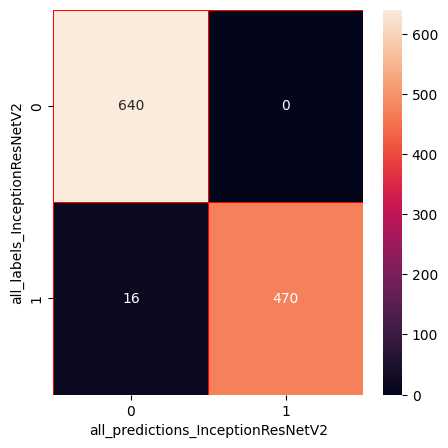

In [33]:
print("val_ds (InceptionResNetV2)")
print("                  ")
print(report_InceptionResNetV2)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, 
                                                  average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2,
                                                           average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_InceptionResNetV2 ,all_predictions_InceptionResNetV2)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_InceptionResNetV2")
plt.ylabel("all_labels_InceptionResNetV2")
plt.show()

In [34]:
loss_val_InceptionResNetV2, accuracy_val_InceptionResNetV2 = model_InceptionResNetV2.evaluate(val_ds) 
print("test loss_InceptionResNetV2: {:.4f}".format(loss_val_InceptionResNetV2))
print("test accuracy_InceptionResNetV2: {:.4f}".format(accuracy_val_InceptionResNetV2))

36/36 [==============================] - 6s 77ms/step - loss: 0.0671 - accuracy: 0.9840
test loss_InceptionResNetV2: 0.0671
test accuracy_InceptionResNetV2: 0.9840


In [35]:
saved_info = {
    'class_names': class_names,
    'all_labels_InceptionResNetV2': all_labels_InceptionResNetV2,
    'all_predictions_InceptionResNetV2': all_predictions_InceptionResNetV2,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'precision_score': precision_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average='weighted'),
    'recall_score': recall_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average='weighted'),
    'f1_score_each': f1_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'Hinge': hinge_loss(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'Jaccard Score': jaccard_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'Log Loss': log_loss(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'Zero-One Loss': zero_one_loss(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('InceptionResNetV2_val_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [36]:
with open('InceptionResNetV2_val_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_InceptionResNetV2'])
print("  ")
print("predictions:", saved_info['all_predictions_InceptionResNetV2'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [0 1 0 ... 1 0 1]
  
predictions: [0 1 0 ... 1 0 1]
  
cm: [[640   0]
 [ 16 470]]
  
1) Accuracy: 0.9857904085257548
  
2) Precision: 0.9861369839275659
  
3) Recall: 0.9857904085257548
  
4) Average F1-score: 0.985759213338108
  
5) F1-score for each type of attack: [0.98765432 0.9832636 ]
  
6) Average ROC AUC: 0.9835390946502058
  
7) Average PR AUC: 0.9812877807746566
  
8) Balanced Accuracy: 1.0
  
9) Hinge: 0.5825932504440497
  
10) Matthews Correlation Coefficient: 0.9713346057825004
  
11) Jaccard Score: 0.9670781893004116
  
12) Log Loss: 0.5121655898986454
  
13) Zero-One Loss: 0.014209591474245165
  
14) Prediction Overhead: 0.4097222222222222
  
15) Specificity: 1.0


## TL + InceptionResNetV2

In [37]:
base_model_InceptionResNetV2.trainable = True
print("Number of layers in the base model: ", len(base_model_InceptionResNetV2.layers))
fine_tune_at_InceptionResNetV2 = int((130/151)*len(base_model_InceptionResNetV2.layers))
for layer in base_model_InceptionResNetV2.layers[:fine_tune_at_InceptionResNetV2]:
  layer.trainable = False
print("frozen layers in the base model from layer 1 to ", fine_tune_at_InceptionResNetV2 )
print("unfrozen layers in the base model from %2d to %3d " % (fine_tune_at_InceptionResNetV2+1,len(base_model_InceptionResNetV2.layers)))

Number of layers in the base model:  780
frozen layers in the base model from layer 1 to  671
unfrozen layers in the base model from 672 to 780 


In [38]:
history= LossHistory()
savepath='./InceptionResNetV2+TL.h5'
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
saveBestModel = kcallbacks.ModelCheckpoint(filepath=savepath, verbose=1, 
                                               save_best_only=True, mode='auto')
model_InceptionResNetV2.compile(loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              optimizer = tf.keras.optimizers.Adam(learning_rate=0.00005/10),
              metrics=['accuracy'])
model_InceptionResNetV2.summary()
len(model_InceptionResNetV2.trainable_variables)

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 sequential (Sequential)     (None, 224, 224, 3)       0         
                                                                 
 tf.math.truediv (TFOpLambd  (None, 224, 224, 3)       0         
 a)                                                              
                                                                 
 tf.math.subtract (TFOpLamb  (None, 224, 224, 3)       0         
 da)                                                             
                                                                 
 inception_resnet_v2 (Funct  (None, 5, 5, 1536)        54336736  
 ional)                                                          
                                                             

70

In [39]:
%%time
fine_tune_epochs = 5
total_epochs =  initial_epochs + fine_tune_epochs
history_fine_InceptionResNetV2 = model_InceptionResNetV2.fit(train_ds, epochs=total_epochs, 
                         initial_epoch=history_InceptionResNetV2.epoch[-1],
                         validation_data=val_ds,
                         callbacks=[early_stop, saveBestModel, history])
# Inference (Detection)
start_time = time.time()
detection_results = model_InceptionResNetV2.predict(val_ds)
end_time = time.time()

detection_time = end_time - start_time

print(f"Detection time: {detection_time} seconds")

Epoch 5/10
213/213 [==============================] - ETA: 0s - loss: 0.0229 - accuracy: 0.9915
Epoch 5: val_loss improved from inf to 0.03148, saving model to ./InceptionResNetV2+TL.h5


/usr/local/lib/python3.9/site-packages/keras/src/engine/training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


213/213 [==============================] - 41s 123ms/step - loss: 0.0229 - accuracy: 0.9915 - val_loss: 0.0315 - val_accuracy: 0.9885
Epoch 6/10
213/213 [==============================] - ETA: 0s - loss: 0.0098 - accuracy: 0.9969
Epoch 6: val_loss did not improve from 0.03148
213/213 [==============================] - 23s 110ms/step - loss: 0.0098 - accuracy: 0.9969 - val_loss: 0.0383 - val_accuracy: 0.9885
Epoch 7/10
213/213 [==============================] - ETA: 0s - loss: 0.0061 - accuracy: 0.9978
Epoch 7: val_loss improved from 0.03148 to 0.00910, saving model to ./InceptionResNetV2+TL.h5
213/213 [==============================] - 24s 111ms/step - loss: 0.0061 - accuracy: 0.9978 - val_loss: 0.0091 - val_accuracy: 0.9956
Epoch 8/10
213/213 [==============================] - ETA: 0s - loss: 0.0070 - accuracy: 0.9981
Epoch 8: val_loss improved from 0.00910 to 0.00737, saving model to ./InceptionResNetV2+TL.h5
213/213 [==============================] - 24s 113ms/step - loss: 0.0070 - 

## InceptionResNetV2 Graph

In [40]:
acc_InceptionResNetV2 += history_fine_InceptionResNetV2.history['accuracy']
val_acc_InceptionResNetV2 += history_fine_InceptionResNetV2.history['val_accuracy']
loss_InceptionResNetV2 += history_fine_InceptionResNetV2.history['loss']
val_loss_InceptionResNetV2 += history_fine_InceptionResNetV2.history['val_loss']

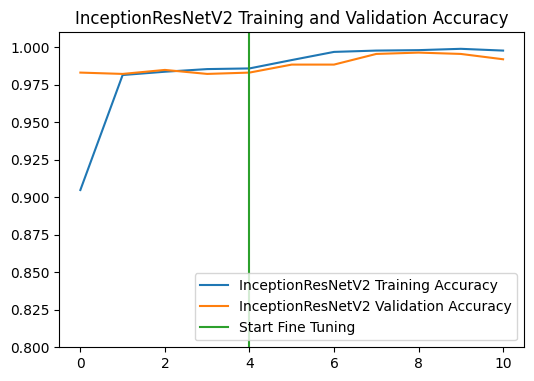

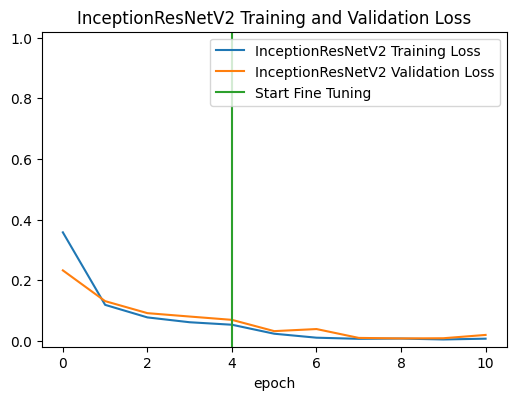

In [41]:
plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 1)
plt.plot(acc_InceptionResNetV2, label='InceptionResNetV2 Training Accuracy')
plt.plot(val_acc_InceptionResNetV2, label='InceptionResNetV2 Validation Accuracy')
plt.ylim([0.8, 1.01])
plt.plot([initial_epochs-1,initial_epochs-1],
          plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='lower right')
plt.title('InceptionResNetV2 Training and Validation Accuracy')
plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 2)
plt.plot(loss_InceptionResNetV2, label='InceptionResNetV2 Training Loss')
plt.plot(val_loss_InceptionResNetV2, label='InceptionResNetV2 Validation Loss')
plt.ylim([-0.02, 1.02])
plt.plot([initial_epochs-1,initial_epochs-1],
         plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='upper right')
plt.title('InceptionResNetV2 Training and Validation Loss')
plt.xlabel('epoch')

training_history = {}
training_history['train_loss'] = history_InceptionResNetV2.history['loss']
training_history['val_loss'] = history_InceptionResNetV2.history['val_loss']
training_history['train_acc'] = history_InceptionResNetV2.history['accuracy']
training_history['val_acc'] = history_InceptionResNetV2.history['val_accuracy']

with open('InceptionResNetV2_TL+ORG.pkl', 'wb') as file:
    pickle.dump(training_history, file)
plt.savefig('InceptionResNetV2_TL+ORG.pdf', format='pdf', dpi=300)
plt.savefig('InceptionResNetV2_TL+ORG.svg', format='svg')
plt.savefig('InceptionResNetV2_TL+ORG.png', format='png', dpi=300)
plt.show()

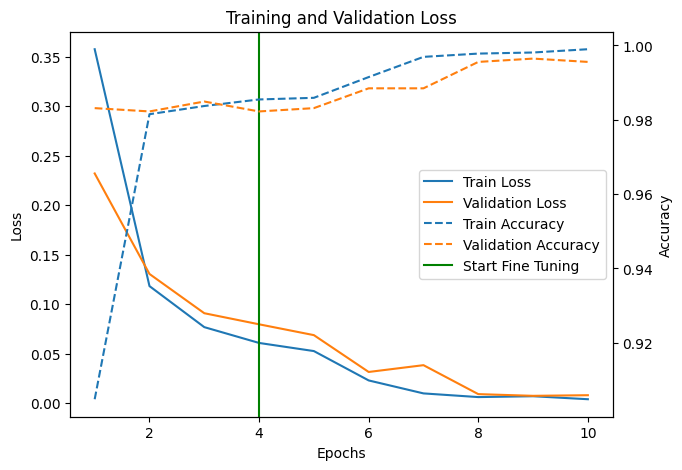

In [42]:
actual_epochs = range(1, total_epochs + 1)
actual_train_loss = loss_InceptionResNetV2[:total_epochs]  
actual_val_loss = val_loss_InceptionResNetV2[:total_epochs]  
actual_train_accuracy = acc_InceptionResNetV2[:total_epochs] 
actual_val_accuracy = val_acc_InceptionResNetV2[:total_epochs]

fig, ax1 = plt.subplots(figsize=(7, 5))
ax1.plot(actual_epochs, actual_train_loss, '-', label='Train Loss')
ax1.plot(actual_epochs, actual_val_loss, '-', label='Validation Loss')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.set_title('Training and Validation Loss')
ax2 = ax1.twinx()
ax2.plot(actual_epochs, actual_train_accuracy, '--', label='Train Accuracy')
ax2.plot(actual_epochs, actual_val_accuracy, '--', label='Validation Accuracy')
ax2.set_ylabel('Accuracy')

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
custom_legend_elements = handles1 + handles2 + [plt.Line2D([0], [0], color='green', label='Start Fine Tuning')]
custom_legend_labels = labels1 + labels2 + ['Start Fine Tuning']
ax1.legend(custom_legend_elements, custom_legend_labels, loc='center right')

ax1.axvline(x=initial_epochs - 1, color='green')
plot_data = {'fig': fig, 'ax1': ax1, 'ax2': ax2}

learning_curve_data = {
    'train_loss': actual_train_loss,
    'val_loss': actual_val_loss,
    'train_acc': actual_train_accuracy,
    'val_acc': actual_val_accuracy
}

with open('InceptionResNetV2+Start Fine Tuning.pkl', 'wb') as file:
    pickle.dump(plot_data, file)
plt.savefig('InceptionResNetV2+Start Fine Tuning.pdf', format='pdf', dpi=300)
plt.savefig('InceptionResNetV2+Start Fine Tuning.svg', format='svg')
plt.savefig('InceptionResNetV2+Start Fine Tuning.png', format='png', dpi=300)
plt.show()

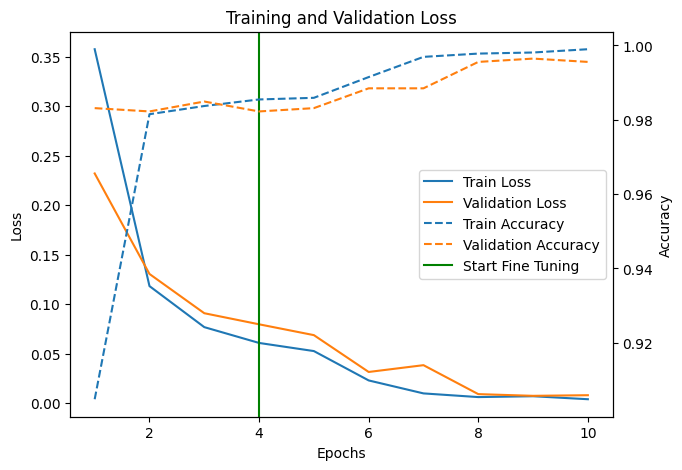

Training Loss: [0.3575995862483978, 0.11824128776788712, 0.07678519934415817, 0.06080267205834389, 0.05259674787521362, 0.022926712408661842, 0.00982081238180399, 0.0061007291078567505, 0.006961460690945387, 0.0039418782107532024]
Validation Loss: [0.2320737987756729, 0.13050314784049988, 0.09084244072437286, 0.07964592427015305, 0.06870358437299728, 0.03147914260625839, 0.03834990784525871, 0.00909761618822813, 0.007368628866970539, 0.007994595915079117]
Training Accuracy: [0.9048318266868591, 0.9814950823783875, 0.9836980700492859, 0.9854604005813599, 0.9859009981155396, 0.9914818406105042, 0.9969158172607422, 0.9977970123291016, 0.9980907440185547, 0.9989719390869141]
Validation Accuracy: [0.9831261038780212, 0.9822379946708679, 0.9849023222923279, 0.9822379946708679, 0.9831261038780212, 0.9884546995162964, 0.9884546995162964, 0.9955595135688782, 0.9964476227760315, 0.9955595135688782]


In [43]:
with open('InceptionResNetV2+Start Fine Tuning.pkl', 'rb') as file:
    learning_curve = pickle.load(file)
    
fig = learning_curve['fig']
ax1 = learning_curve['ax1']
ax2 = learning_curve['ax2']
plt.show()

train_loss = learning_curve_data['train_loss']
val_loss = learning_curve_data['val_loss']
train_acc = learning_curve_data['train_acc']
val_acc = learning_curve_data['val_acc']
print("Training Loss:", learning_curve_data['train_loss'])
print("Validation Loss:", learning_curve_data['val_loss'])
print("Training Accuracy:", learning_curve_data['train_acc'])
print("Validation Accuracy:", learning_curve_data['val_acc'])

## Test_ds (InceptionResNetV2) + TL

Predictions:
 [1 0 0 0 0 1 1 1 1 0 0 0 0 0 1 0 0 0 0 0 1 1 0 1 1 0 1 0 1 0 1 0 0 0 0 1 0
 0 0 0 0 1 1 0 1 0 0 0 1 0 0 0 0 1 1 0 1 0 1 0 1 1 0 1 0 1 1 0 0 0 1 0 0 1
 0 1 1 0 0 0 0 1 0 1 1 0 1 0 0 0 1 1 1 1 0 0 1 0 0 0 0 0 1 0 0 1 0 0 1 0 1
 0 1 1 0 1 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 1 0 1 0 0 0 1 0 0 1 1 0 1 0 0 1 1
 0 0 0 0 0 1 0 1 1 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 1 1 0 1 1 1 1 1 0 0 1 0 1
 1 0 1 0 0 1 0 1 0 0 1 0 1 1 0 0 1 0 1 1 1 0 1 0 0 1 0 0 1 1 0 0 1 0 1 1 0
 1 0 0 0 1 0 1 0 1 1 0 0 0 0 1 0 1 1 1 1 0 1 0 1 1 0 0 0 0 1 0 1 1 1 0 0 0
 0 0 1 0 0 1 0 0 0 1 0 0 1 1 1 1 0 0 0 0 1 0 1 1 0 0 0 0 1 1 0 0 1 0 1 1 0
 0 1 0 1 0 0 1 1 1 1 0 1 0 1 1 1 0 0 1 0 0 0 0 1 1 0 0 0 0 1 1 1 1 0 0 0 0
 1 1 1 0 0 0 1 1 0 1 1 0 1 1 0 0 1 1 1 1 0 0 1 0 0 1 0 0 0 1 0 0 0 0 0 0 0
 1 1 0 1 1 1 0 0 1 1 0 1 1 0 0 0 1 0 0 0 0 1 1 1 0 0 1 0 0 1 1 0 1 0 1 0 1
 1 1 0 0 0 1 0 0 0 0 0 0 1 0 0 1 0 1 1 0 0 0 1 1 0 0 0 0 1 1 0 0 0 0 0 1 1
 1 1 0 1 0 1 1 1 0 1 0 1 0 0 0 1 1 0 1 0 1 0 0 1 1 1 1 0 1 0 0 0 0 1 1 1 1
 0 1 0 0 0 

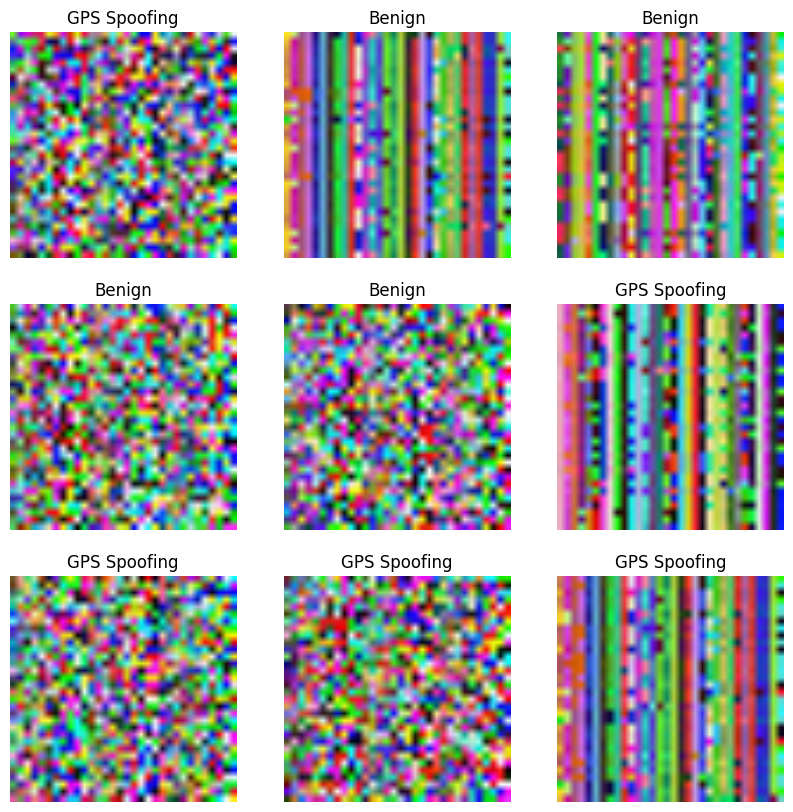

In [44]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_InceptionResNetV2 = []
all_labels_InceptionResNetV2 = []

for image_batch, label_batch in test_ds.as_numpy_iterator():
    predictions = model_InceptionResNetV2.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_InceptionResNetV2.append(predictions)
    all_labels_InceptionResNetV2.append(label_batch)

all_predictions_InceptionResNetV2 = np.concatenate(all_predictions_InceptionResNetV2)
all_labels_InceptionResNetV2 = np.concatenate(all_labels_InceptionResNetV2)
print('Predictions:\n', all_predictions_InceptionResNetV2)
print('Labels:\n', all_labels_InceptionResNetV2)
report_InceptionResNetV2 = classification_report(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, 
                                                 target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_InceptionResNetV2[i]])
    plt.axis("off")

test_ds (InceptionResNetV2)
                  
              precision    recall  f1-score   support

      Benign       0.99      1.00      1.00       325
GPS Spoofing       1.00      0.99      1.00       251

    accuracy                           1.00       576
   macro avg       1.00      1.00      1.00       576
weighted avg       1.00      1.00      1.00       576

                  
1) Accuracy: 0.9965277777777778
                  
2) Precision: 0.9965490146109413
                  
3) Recall: 0.9965277777777778
                  
4) Average F1-score: 0.9965261588275394
                  
5) F1-score for each type of attack: [0.99693252 0.996     ]
                  
6) Average ROC AUC: 0.9960159362549801
                  
7) Average PR AUC: 0.9955040947321824
                  
8) Balanced Accuracy: 0.9960159362549801
                  
9) Hinge: 0.5677083333333334
                  
10) Matthews Correlation Coefficient: 0.9929574005382102
                  
11) Jaccard Score

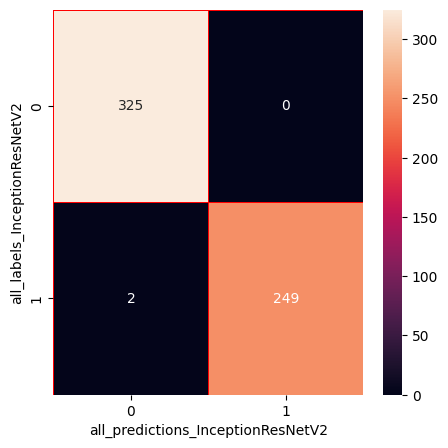

In [45]:
print("test_ds (InceptionResNetV2)")
print("                  ")
print(report_InceptionResNetV2)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, 
                                                  average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2,
                                                           average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_InceptionResNetV2 ,all_predictions_InceptionResNetV2)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_InceptionResNetV2")
plt.ylabel("all_labels_InceptionResNetV2")
plt.show()

In [46]:
loss_test_InceptionResNetV2, accuracy_test_InceptionResNetV2 = model_InceptionResNetV2.evaluate(test_ds) 
print("test loss_InceptionResNetV2: {:.4f}".format(loss_test_InceptionResNetV2))
print("test accuracy_InceptionResNetV2: {:.4f}".format(accuracy_test_InceptionResNetV2))

18/18 [==============================] - 2s 78ms/step - loss: 0.0314 - accuracy: 0.9931
test loss_InceptionResNetV2: 0.0314
test accuracy_InceptionResNetV2: 0.9931


In [47]:
saved_info = {
    'class_names': class_names,
    'all_labels_InceptionResNetV2': all_labels_InceptionResNetV2,
    'all_predictions_InceptionResNetV2': all_predictions_InceptionResNetV2,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'precision_score': precision_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average='weighted'),
    'recall_score': recall_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average='weighted'),
    'f1_score_each': f1_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'Hinge': hinge_loss(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'Jaccard Score': jaccard_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'Log Loss': log_loss(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'Zero-One Loss': zero_one_loss(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('InceptionResNetV2_test(TL)_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [48]:
with open('InceptionResNetV2_test(TL)_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_InceptionResNetV2'])
print("  ")
print("predictions:", saved_info['all_predictions_InceptionResNetV2'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [1 0 0 0 0 1 1 1 1 0 0 0 0 0 1 0 0 0 0 0 1 1 0 1 1 0 1 0 1 0 1 0 0 0 0 1 0
 0 0 0 0 1 1 0 1 0 0 0 1 0 0 0 0 1 1 0 1 0 1 0 1 1 0 1 0 1 1 0 0 0 1 0 0 1
 0 1 1 0 0 0 0 1 0 1 1 0 1 0 0 0 1 1 1 1 0 0 1 0 0 0 0 0 1 0 0 1 0 0 1 0 1
 0 1 1 0 1 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 1 0 1 0 0 0 1 0 0 1 1 0 1 0 0 1 1
 0 0 0 0 0 1 0 1 1 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 1 1 0 1 1 1 1 1 0 0 1 0 1
 1 0 1 0 0 1 0 1 0 0 1 0 1 1 0 0 1 0 1 1 1 0 1 0 0 1 0 0 1 1 0 0 1 0 1 1 0
 1 0 0 0 1 0 1 0 1 1 0 0 0 0 1 0 1 1 1 1 0 1 0 1 1 0 0 0 0 1 0 1 1 1 0 0 0
 0 0 1 0 0 1 0 0 0 1 0 0 1 1 1 1 0 0 0 0 1 0 1 1 0 0 0 0 1 1 0 0 1 0 1 1 0
 0 1 0 1 0 0 1 1 1 1 0 1 0 1 1 1 0 0 1 0 0 0 0 1 1 0 0 0 1 1 1 1 1 0 0 0 0
 1 1 1 0 0 0 1 1 0 1 1 0 1 1 0 0 1 1 1 1 0 0 1 0 0 1 0 0 0 1 0 0 0 0 0 0 0
 1 1 0 1 1 1 0 0 1 1 0 1 1 0 0 0 1 0 0 0 0 1 1 1 0 0 1 0 0 1 1 0 1 0 1 0 1
 1 1 0 0 0 1 0 0 0 0 0 0 1 0 0 1 0 1 1 0 0 0 1 1 0 0 0 0 1 1 0 0 0 0 0 1 1
 1 1 0 1 0 1 1 1 0 1 0 1 0 0 0 1 1 0 1 0 1 0 0 1 1 1 1 0 1 0 0 0 0

## Val_ds (InceptionResNetV2) + TL

Predictions:
 [1 1 0 ... 1 1 1]
Labels:
 [1 1 0 ... 1 1 1]


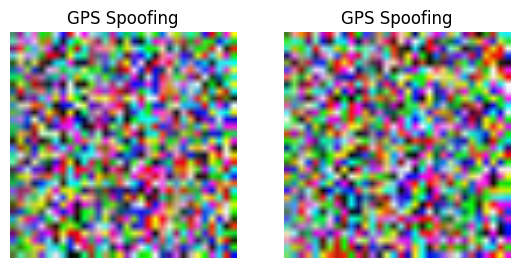

In [49]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_InceptionResNetV2 = []
all_labels_InceptionResNetV2 = []

for image_batch, label_batch in val_ds.as_numpy_iterator():
    predictions = model_InceptionResNetV2.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_InceptionResNetV2.append(predictions)
    all_labels_InceptionResNetV2.append(label_batch)
all_predictions_InceptionResNetV2 = np.concatenate(all_predictions_InceptionResNetV2)
all_labels_InceptionResNetV2 = np.concatenate(all_labels_InceptionResNetV2)
print('Predictions:\n', all_predictions_InceptionResNetV2)
print('Labels:\n', all_labels_InceptionResNetV2)

report_InceptionResNetV2 = classification_report(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, 
                                                 target_names=class_names_s)

plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_InceptionResNetV2[i]])
    plt.axis("off")

val_ds (InceptionResNetV2)
                  
              precision    recall  f1-score   support

      Benign       0.99      1.00      1.00       644
GPS Spoofing       1.00      0.99      0.99       482

    accuracy                           0.99      1126
   macro avg       1.00      0.99      0.99      1126
weighted avg       0.99      0.99      0.99      1126

                  
1) Accuracy: 0.9946714031971581
                  
2) Precision: 0.9947205902445689
                  
3) Recall: 0.9946714031971581
                  
4) Average F1-score: 0.9946670703476348
                  
5) F1-score for each type of attack: [0.99536321 0.99373695]
                  
6) Average ROC AUC: 0.9937759336099585
                  
7) Average PR AUC: 0.992880464022759
                  
8) Balanced Accuracy: 0.9937759336099585
                  
9) Hinge: 0.5772646536412078
                  
10) Matthews Correlation Coefficient: 0.9891592408860137
                  
11) Jaccard Score: 

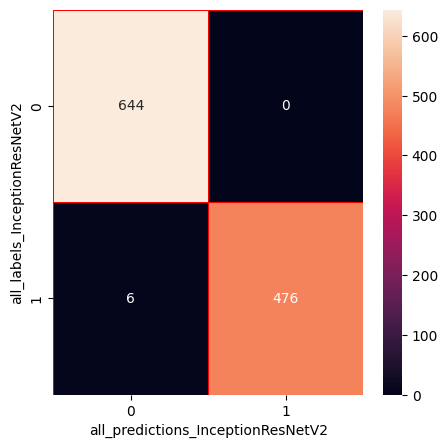

In [50]:
print("val_ds (InceptionResNetV2)")
print("                  ")
print(report_InceptionResNetV2)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, 
                                                  average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2,
                                                           average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_InceptionResNetV2 , all_predictions_InceptionResNetV2)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_InceptionResNetV2 ,all_predictions_InceptionResNetV2)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_InceptionResNetV2")
plt.ylabel("all_labels_InceptionResNetV2")
plt.show()

In [51]:
loss_val_InceptionResNetV2, accuracy_val_InceptionResNetV2 = model_InceptionResNetV2.evaluate(val_ds)
print("test loss_InceptionResNetV2: {:.4f}".format(loss_val_InceptionResNetV2))
print("test accuracy_InceptionResNetV2: {:.4f}".format(accuracy_val_InceptionResNetV2))

36/36 [==============================] - 9s 129ms/step - loss: 0.0151 - accuracy: 0.9929
test loss_InceptionResNetV2: 0.0151
test accuracy_InceptionResNetV2: 0.9929


In [52]:
saved_info = {
    'class_names': class_names,
    'all_labels_InceptionResNetV2': all_labels_InceptionResNetV2,
    'all_predictions_InceptionResNetV2': all_predictions_InceptionResNetV2,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'precision_score': precision_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average='weighted'),
    'recall_score': recall_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average='weighted'),
    'f1_score_each': f1_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'Hinge': hinge_loss(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'Jaccard Score': jaccard_score(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'Log Loss': log_loss(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'Zero-One Loss': zero_one_loss(all_labels_InceptionResNetV2, all_predictions_InceptionResNetV2),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('InceptionResNetV2_val(TL)_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [53]:
with open('InceptionResNetV2_val(TL)_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)
    
print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_InceptionResNetV2'])
print("  ")
print("predictions:", saved_info['all_predictions_InceptionResNetV2'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [1 1 0 ... 1 1 1]
  
predictions: [1 1 0 ... 1 1 1]
  
cm: [[644   0]
 [  6 476]]
  
1) Accuracy: 0.9946714031971581
  
2) Precision: 0.9947205902445689
  
3) Recall: 0.9946714031971581
  
4) Average F1-score: 0.9946670703476348
  
5) F1-score for each type of attack: [0.99536321 0.99373695]
  
6) Average ROC AUC: 0.9937759336099585
  
7) Average PR AUC: 0.992880464022759
  
8) Balanced Accuracy: 1.0
  
9) Hinge: 0.5772646536412078
  
10) Matthews Correlation Coefficient: 0.9891592408860137
  
11) Jaccard Score: 0.9875518672199171
  
12) Log Loss: 0.19206209621199213
  
13) Zero-One Loss: 0.005328596802841923
  
14) Prediction Overhead: 0.4097222222222222
  
15) Specificity: 1.0


## Load the saved model and learning curve

In [54]:
new_model = tf.keras.models.load_model('./InceptionResNetV2+TL.h5')

In [55]:
for layer in new_model.layers:
    print(layer.name)
    weights = layer.get_weights()
    for weight in weights:
        print(weight)

input_2
sequential
tf.math.truediv
tf.math.subtract
inception_resnet_v2
[[[[-1.63356900e-01 -6.17088936e-03  1.31041095e-01  3.69789302e-02
    -1.25390440e-01  5.64914942e-02 -3.34196649e-02  3.85071449e-02
    -1.42315730e-01 -4.65757668e-01  2.88656913e-02 -2.29952231e-01
     2.93689221e-01  3.70038033e-01  1.04863588e-02 -5.95548749e-02
     4.02644416e-03 -6.59151852e-01  4.78085995e-01  2.54727662e-01
    -5.34945633e-03  4.83594924e-01 -2.09189281e-01  5.81100464e-01
    -1.35197695e-02  4.32890505e-01 -4.08778906e-01  1.29318982e-01
     2.92476296e-01  1.29870713e-01 -7.00813308e-02 -1.88857064e-01]
   [ 1.76385362e-02  1.80546902e-02 -6.06614277e-02  1.45480633e-01
    -6.07440658e-02  2.83849817e-02 -4.47433330e-02 -4.81597036e-02
     4.65660952e-02 -6.00845039e-01 -4.37628180e-02  5.42540371e-01
     4.20721650e-01  4.56823856e-01 -4.83046435e-02  1.23057008e-01
    -3.67723137e-01 -5.96955895e-01 -3.82778585e-01 -1.69061795e-01
     3.99024747e-02  5.07815599e-01  1.8630

In [56]:
print(new_model.get_config())

{'name': 'model', 'trainable': True, 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_input_shape': (None, 224, 224, 3), 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'input_2'}, 'registered_name': None, 'name': 'input_2', 'inbound_nodes': []}, {'module': 'keras', 'class_name': 'Sequential', 'config': {'name': 'sequential', 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_input_shape': (None, 224, 224, 3), 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'random_flip_input'}, 'registered_name': None}, {'module': 'keras.layers', 'class_name': 'RandomFlip', 'config': {'name': 'random_flip', 'trainable': True, 'dtype': 'float32', 'mode': 'horizontal_and_vertical', 'seed': None}, 'registered_name': None, 'build_config': {'input_shape': (None, 224, 224, 3)}}, {'module': 'keras.layers', 'class_name': 'RandomRotation', 'config': {'name': 'random_rotation', 'trainable': True, 'dtype': 'float32', 